# PARCIAL – ANÁLISIS
**Caso de estudio:** Predicción de diabetes con Python, visualización y redes neuronales
**Nombre:** Lizeth Luna  |  **Docente:** Ing. Carlos Carrascal  |  **Fecha:** 14/10/2026

**Dataset:** [Diabetes – Kaggle (datascikhan)](https://www.kaggle.com/datasets/datascikhan/diabetes) · archivo `diabetes_large_dataset.csv`

> ⚠️ Ejercicio académico. Los modelos no deben usarse para diagnosticar pacientes ni para tomar decisiones clínicas.

**Cómo ejecutar:** menú *Entorno de ejecución → Ejecutar todo*. En el Bloque 1 aparece un botón *Choose files*: allí subo `archive.zip` (o el `.csv`).

In [1]:
# ===== Configuración general =====
# Importo las librerías que voy a usar y fijo la semilla para que mis resultados se puedan reproducir.
import io, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42                      # semilla fija para que los resultados sean reproducibles
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

RUTA_LOCAL = None              # solo lo uso si ejecuto FUERA de Colab (ruta al .zip o .csv)
COLORES = {"Sin diabetes": "#4C78A8", "Con diabetes": "#E4572E"}

---
# Bloque 1. Carga e inspección de datos

In [2]:
# ===== 1.1 Carga del archivo con botón de subida =====
# Cargo el archivo con un botón de subida (files.upload). Sirve con el .zip de Kaggle o con el .csv.
try:
    from google.colab import files
    subido = files.upload()                      # aparece el botón "Choose files"
    nombre = list(subido.keys())[0]
    contenido = io.BytesIO(subido[nombre])
except ImportError:                              # fuera de Colab
    nombre = RUTA_LOCAL
    contenido = io.BytesIO(open(RUTA_LOCAL, "rb").read())

if nombre.lower().endswith(".zip"):              # el archivo de Kaggle viene comprimido
    z = zipfile.ZipFile(contenido)
    print("Contenido del zip:", z.namelist())
    csv_interno = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
    df = pd.read_csv(z.open(csv_interno))
else:
    df = pd.read_csv(contenido)

print(f"\nArchivo cargado: {nombre}")
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")

Saving archive.zip to archive.zip
Contenido del zip: ['diabetes_large_dataset.csv']

Archivo cargado: archive.zip
Filas: 100,000 | Columnas: 209


In [3]:
# ===== 1.2 Primeras 10 y últimas 5 filas =====
# Muestro las primeras 10 y las últimas 5 filas para ver cómo viene el dataset.
print("Primeras 10 filas:")
display(df.head(10))
print("Últimas 5 filas:")
display(df.tail(5))

Primeras 10 filas:


,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,employment_status,occupation_category,income_level,annual_income,household_size,dependents,residential_area_type,urban_rural,insurance_status,height_cm,...,region,state_province,city_category,climate_zone,urbanization_level,cardiovascular_risk_score,metabolic_risk_score,obesity_risk_score,hypertension_risk_score,kidney_risk_score,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
0,P000001,R00000001,57.0,51-60,Male,Male,Black,Black,Married,Some College,Employed,Professional,Upper-Middle,135252.92,2,1,Urban,Urban,Uninsured,182.5,...,Southwest,State A,Urban,Tropical,Low,13.3,16.1,18.6,33.9,0.3,2.4,86.8,86.0,64.7,89.4,1,2,0,NaN,No Diabetes
1,P000002,R00000002,47.0,41-50,Female,Female,White,White,Married,High School,Unemployed,Unemployed,Middle,57826.74,4,2,Urban,Urban,Insured,174.8,...,East,Province B,Small Town,Temperate,High,26.7,20.8,0.0,33.1,2.0,2.7,85.5,86.2,78.4,80.0,3,0,0,NaN,No Diabetes
2,P000003,R00000003,59.0,51-60,Male,Male,Black,Black,Married,Some College,Employed,Professional,Lower-Middle,31057.78,4,3,Suburban,Suburban,Insured,187.3,...,Midwest,State B,Suburban,Temperate,Medium,25.3,2.3,0.0,6.8,13.4,19.3,66.0,66.1,56.7,64.7,2,0,1,1.0,Type 2
3,P000004,R00000004,72.0,71-90,Female,Female,Black,Black,Single,Master,Retired,Technical,Middle,33333.87,4,2,Suburban,Suburban,Uninsured,160.7,...,Midwest,State C,Metropolitan,Arid,Low,57.0,46.4,41.8,76.8,35.2,0.9,61.8,64.4,68.6,59.6,3,0,0,0.0,No Diabetes
4,P000005,R00000005,46.0,41-50,Male,Male,Hispanic,Hispanic,Married,Bachelor,Employed,Professional,Middle,36989.40,1,0,Urban,Urban,Government,174.9,...,Northeast,State A,Small Town,Temperate,High,35.7,14.8,11.1,23.1,8.8,6.3,80.4,81.8,73.0,76.7,1,0,2,0.0,No Diabetes
5,P000006,R00000006,46.0,41-50,Female,Female,White,White,Divorced,Some College,Employed,Professional,Upper-Middle,106236.11,4,2,Suburban,Suburban,Government,NaN,...,Southwest,Province B,Suburban,Arid,Low,8.3,15.4,11.8,24.7,7.2,2.5,81.5,82.2,79.5,83.4,1,0,0,0.0,No Diabetes
6,P000007,R00000007,73.0,71-90,Female,Female,Black,Black,Widowed,Bachelor,Retired,Professional,Upper-Middle,55958.85,3,1,Urban,Urban,Underinsured,167.2,...,Southwest,Province B,Urban,Temperate,Medium,32.6,9.6,0.4,48.8,25.9,5.9,71.0,72.6,50.2,70.7,5,0,0,1.0,Type 2
7,P000008,R00000008,61.0,61-70,Male,Male,Mixed,Mixed,Married,Bachelor,Disabled,Service,Upper-Middle,72824.38,3,1,Urban,Urban,Insured,171.5,...,West,Province B,Rural,Arid,High,62.1,23.3,18.1,49.6,52.7,4.2,66.2,65.7,90.6,74.4,3,2,0,0.0,No Diabetes
8,P000009,R00000009,42.0,41-50,Male,Male,Black,Black,Married,Some College,Retired,Service,High,106824.39,6,5,Suburban,Suburban,Insured,187.2,...,Southeast,State C,Small Town,Continental,High,18.6,0.0,0.0,7.0,10.8,14.9,81.0,79.4,74.4,86.1,1,0,0,0.0,No Diabetes
9,P000010,R00000010,58.0,51-60,Male,Male,Asian,Asian,Married,High School,Retired,Service,Middle,72170.01,4,2,Urban,Urban,Underinsured,168.3,...,South,Province C,Small Town,Tropical,High,32.1,19.2,15.5,41.2,44.0,19.8,71.8,72.1,57.9,83.1,4,0,0,1.0,Type 2


Últimas 5 filas:


,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,employment_status,occupation_category,income_level,annual_income,household_size,dependents,residential_area_type,urban_rural,insurance_status,height_cm,...,region,state_province,city_category,climate_zone,urbanization_level,cardiovascular_risk_score,metabolic_risk_score,obesity_risk_score,hypertension_risk_score,kidney_risk_score,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
99995,P099996,R00099996,46.0,41-50,Male,Male,Black,Black,Divorced,Bachelor,Unemployed,Service,Lower-Middle,18731.86,3,2,Suburban,Suburban,Insured,172.6,...,Southeast,State C,Urban,Temperate,High,39.8,7.7,6.5,13.0,7.9,0.3,73.2,69.2,53.4,58.2,2,0,1,0.0,No Diabetes
99996,P099997,R00099997,41.0,41-50,Female,Female,Asian,Asian,Married,Some College,Employed,Technical,Middle,50387.85,8,6,Suburban,Suburban,Underinsured,145.3,...,Midwest,State A,Suburban,Continental,Medium,25.0,27.6,44.7,24.7,22.7,4.0,77.6,77.4,77.6,86.3,4,2,0,0.0,No Diabetes
99997,P099998,R00099998,56.0,51-60,Female,Female,White,White,Widowed,High School,Employed,Manual,Middle,70485.77,5,3,Suburban,Suburban,Insured,173.0,...,West,State B,Metropolitan,Temperate,Low,9.2,0.0,0.0,12.8,0.5,0.0,94.0,96.4,58.7,83.4,0,1,0,0.0,No Diabetes
99998,P099999,R00099999,46.0,41-50,Female,Female,White,White,Married,Bachelor,Employed,Professional,Upper-Middle,93835.40,2,0,Urban,Urban,Underinsured,156.6,...,West,State B,Urban,Continental,High,37.3,17.5,68.1,42.6,23.7,7.6,64.9,67.2,55.8,60.5,4,3,0,0.0,No Diabetes
99999,P100000,R00100000,51.0,51-60,Female,Female,Native American,Native American,Married,High School,Employed,Retired,Middle,29865.91,4,2,Rural,Rural,Insured,150.0,...,Northeast,Province B,Rural,Arid,High,34.9,26.1,33.0,47.9,16.6,0.0,80.9,71.0,82.9,84.9,4,2,0,0.0,No Diabetes


In [4]:
# ===== 1.3 Número de registros, columnas y tipos de datos =====
# Cuento filas y columnas y reviso el tipo de dato de cada columna.
print(f"Registros (filas): {df.shape[0]:,}")
print(f"Variables (columnas): {df.shape[1]}")
print("\nCantidad de columnas por tipo de dato:")
print(df.dtypes.value_counts())

print("\nVariables categóricas (texto):", df.select_dtypes(exclude="number").shape[1])
print("Variables numéricas:", df.select_dtypes(include="number").shape[1])

Registros (filas): 100,000
Variables (columnas): 209

Cantidad de columnas por tipo de dato:
float64    102
object      92
int64       15
Name: count, dtype: int64

Variables categóricas (texto): 92
Variables numéricas: 117


In [5]:
# ===== 1.4 Valores nulos y duplicados =====
# Calculo cuántos nulos tiene cada columna y reviso si hay filas duplicadas o identificadores repetidos.
nulos = df.isna().sum()
resumen_nulos = pd.DataFrame({"nulos": nulos, "% nulos": (nulos / len(df) * 100).round(2)})
resumen_nulos = resumen_nulos[resumen_nulos["nulos"] > 0].sort_values("nulos", ascending=False)
print(f"Columnas con al menos un nulo: {len(resumen_nulos)} de {df.shape[1]}")
display(resumen_nulos.head(25))

print("\nFilas completamente duplicadas:", df.duplicated().sum())
for c in ["patient_id", "record_id"]:
    if c in df.columns:
        print(f"Valores repetidos en {c}:", df[c].duplicated().sum())

Columnas con al menos un nulo: 43 de 209


,nulos,% nulos
age_at_menopause,82257,82.26
fasting_insulin_uIU_ml,10178,10.18
self_management_score,10177,10.18
urine_albumin_mg_g,10134,10.13
medication_adherence_percent,10054,10.05
folate_ng_ml,10045,10.04
ferritin_ng_ml,10022,10.02
vitamin_d_ng_ml,10018,10.02
public_transport_access,10003,10.00
c_peptide_ng_ml,9948,9.95



Filas completamente duplicadas: 0
Valores repetidos en patient_id: 0
Valores repetidos en record_id: 0


### Variable objetivo
El archivo trae dos columnas relacionadas con el diagnóstico: `diabetes_status` (numérica, con valores 0/1 y **nulos**) y `diabetes_type` (texto: *No Diabetes, Type 2, Type 1, Gestational Diabetes, Other Diabetes*).

Como mi problema es de **clasificación binaria** (con diabetes / sin diabetes), construí una variable `diabetes`:
- `0` → `diabetes_type == "No Diabetes"`
- `1` → cualquier otro tipo de diabetes (Tipo 1, Tipo 2, gestacional u otra)

**Por qué esta es la variable objetivo:** es lo que quiero predecir según el enunciado (si el paciente tiene diabetes) y es la información que representa directamente el diagnóstico; todas las demás columnas son características del paciente que uso para predecirla.

Usé `diabetes_type` como fuente principal porque está casi completa (le faltan unos 550 valores) y `diabetes_status` solo para rellenar las filas donde `diabetes_type` estaba vacío. Si ambas estaban vacías, **eliminé la fila** (fueron 42), porque no puedo inventar el diagnóstico real de un paciente.

In [6]:
# ===== 1.5 Construcción de la variable objetivo =====
# Construyo la variable objetivo binaria (1 = con diabetes, 0 = sin diabetes) y elimino las filas donde no puedo saber el diagnóstico.
print("Cruce entre diabetes_type y diabetes_status (incluye nulos):")
display(pd.crosstab(df["diabetes_type"].fillna("(nulo)"), df["diabetes_status"].fillna(-1)
                    .map({-1: "(nulo)", 0: "0", 1: "1"}), margins=True))

tipo = df["diabetes_type"]
df["diabetes"] = np.where(tipo.notna(), (tipo != "No Diabetes").astype(float), df["diabetes_status"])

sin_objetivo = df["diabetes"].isna().sum()
print(f"\nFilas sin objetivo (ambas columnas vacías): {sin_objetivo}")
df = df.dropna(subset=["diabetes"]).copy()
df["diabetes"] = df["diabetes"].astype(int)

print("\nDistribución de la variable objetivo:")
dist = df["diabetes"].value_counts().rename({0: "Sin diabetes", 1: "Con diabetes"})
display(pd.DataFrame({"pacientes": dist, "%": (dist / len(df) * 100).round(2)}))

Cruce entre diabetes_type y diabetes_status (incluye nulos):


diabetes_status,(nulo),0,1,All
diabetes_type,,,,
(nulo),42,0,505,547
Gestational Diabetes,1,0,107,108
No Diabetes,1401,70573,0,71974
Other Diabetes,47,0,2127,2174
Type 1,0,0,3,3
Type 2,529,0,24665,25194
All,2020,70573,27407,100000



Filas sin objetivo (ambas columnas vacías): 42

Distribución de la variable objetivo:


,pacientes,%
diabetes,,
Sin diabetes,71974,72.0
Con diabetes,27984,28.0


### Diccionario de datos
Generé el diccionario automáticamente con **nombre, tipo, nulos, valores únicos, ejemplo, grupo y significado** de cada variable (210 en total, contando la variable objetivo que creé). Escribí a mano el significado de las variables más importantes; para el resto dejé el nombre legible, porque el dataset **no trae documentación oficial** de cada columna y el grupo y significado de esas variables los inferí a partir del nombre. También lo exporté a `diccionario_datos.csv`.

In [7]:
# ===== 1.6 Diccionario de datos =====
# Construyo el diccionario de datos: nombre, tipo, nulos, valores únicos, ejemplo, grupo y significado de cada variable.
SIGNIFICADO = {
    "patient_id": "Identificador del paciente", "record_id": "Identificador del registro",
    "age": "Edad en años", "age_group": "Grupo de edad (rangos)", "sex": "Sexo biológico",
    "gender": "Género", "ethnicity": "Etnia", "race_group": "Grupo racial",
    "marital_status": "Estado civil", "education_level": "Nivel educativo",
    "employment_status": "Situación laboral", "income_level": "Nivel de ingresos (categoría)",
    "annual_income": "Ingreso anual", "insurance_status": "Tipo de seguro de salud",
    "height_cm": "Estatura (cm)", "weight_kg": "Peso (kg)", "bmi": "Índice de masa corporal (kg/m²)",
    "bmi_category": "Categoría de IMC", "waist_circumference_cm": "Circunferencia de cintura (cm)",
    "hip_circumference_cm": "Circunferencia de cadera (cm)", "waist_to_hip_ratio": "Relación cintura/cadera",
    "body_fat_percentage": "Porcentaje de grasa corporal",
    "fasting_glucose_mg_dl": "Glucosa en ayunas (mg/dL)", "random_glucose_mg_dl": "Glucosa al azar (mg/dL)",
    "post_meal_glucose_mg_dl": "Glucosa posprandial (mg/dL)", "two_hour_glucose_mg_dl": "Glucosa a las 2 h de la prueba de tolerancia (mg/dL)",
    "glucose_variability": "Variabilidad de la glucosa", "hba1c_percent": "Hemoglobina glicosilada HbA1c (%)",
    "estimated_average_glucose_mg_dl": "Glucosa promedio estimada (mg/dL)",
    "fasting_insulin_uIU_ml": "Insulina en ayunas (µIU/mL)", "c_peptide_ng_ml": "Péptido C (ng/mL)",
    "insulin_resistance_index": "Índice de resistencia a la insulina",
    "systolic_bp": "Presión arterial sistólica (mmHg)", "diastolic_bp": "Presión arterial diastólica (mmHg)",
    "heart_rate": "Frecuencia cardíaca (lpm)", "hypertension_status": "Estado de hipertensión",
    "total_cholesterol_mg_dl": "Colesterol total (mg/dL)", "ldl_mg_dl": "Colesterol LDL (mg/dL)",
    "hdl_mg_dl": "Colesterol HDL (mg/dL)", "triglycerides_mg_dl": "Triglicéridos (mg/dL)",
    "creatinine_mg_dl": "Creatinina (mg/dL)", "egfr_ml_min_1_73m2": "Tasa de filtración glomerular estimada",
    "family_history_diabetes": "Antecedente familiar de diabetes", "father_diabetes": "El padre tiene diabetes",
    "mother_diabetes": "La madre tiene diabetes", "sibling_diabetes": "Algún hermano tiene diabetes",
    "smoking_status": "Estado de fumador", "alcohol_use": "Consumo de alcohol",
    "physical_activity_level": "Nivel de actividad física", "exercise_minutes_per_week": "Minutos de ejercicio por semana",
    "daily_steps": "Pasos diarios", "sleep_hours": "Horas de sueño", "stress_level": "Nivel de estrés",
    "diet_quality_score": "Puntaje de calidad de la dieta", "daily_calorie_intake": "Ingesta calórica diaria",
    "sugar_grams_per_day": "Gramos de azúcar por día", "fiber_grams_per_day": "Gramos de fibra por día",
    "hypertension": "Diagnóstico de hipertensión", "hyperlipidemia": "Diagnóstico de hiperlipidemia",
    "cardiovascular_disease": "Enfermedad cardiovascular", "kidney_disease": "Enfermedad renal",
    "obesity_diagnosis": "Diagnóstico de obesidad", "metabolic_syndrome": "Síndrome metabólico",
    "prediabetes_history": "Antecedente de prediabetes", "gestational_diabetes_history": "Antecedente de diabetes gestacional",
    "previous_diabetes_diagnosis": "Diagnóstico previo de diabetes (¡fuga de información!)",
    "diabetes_medication": "Toma medicación para diabetes (¡fuga!)", "metformin_use": "Usa metformina (¡fuga!)",
    "insulin_use": "Usa insulina (¡fuga!)", "diabetes_complication_count": "Número de complicaciones de diabetes (¡fuga!)",
    "diabetes_risk_score": "Puntaje de riesgo de diabetes (¡fuga!)",
    "diabetes_status": "Estado de diabetes (0/1, con nulos)", "diabetes_type": "Tipo de diabetes (texto)",
    "diabetes": "VARIABLE OBJETIVO creada aquí: 1 = con diabetes, 0 = sin diabetes",
    "overall_health_score": "Puntaje global de salud (compuesto; se audita por posible fuga)",
    "quality_of_life_score": "Puntaje de calidad de vida",
    "chronic_condition_count": "Número de condiciones crónicas (¡fuga: el conteo incluye la diabetes!)", "hospitalization_history": "Historial de hospitalizaciones",
    "emergency_visit_history": "Historial de visitas a urgencias", "country": "País", "region": "Región",
}

REGLAS_GRUPO = [
    ("Identificación", ["patient_id", "record_id"]),
    ("Antecedentes familiares", ["family_history", "father", "mother", "sibling"]),
    ("Medicación/Tratamiento", ["medication", "metformin", "insulin_use", "sulfonylurea", "sglt2", "glp1", "dpp4", "statin", "adherence"]),
    ("Puntajes", ["score"]),
    ("Complicaciones/Historia clínica", ["diabetic", "hypoglycemia", "hyperglycemia", "ketoacidosis", "complication", "hospitalization",
                                         "emergency", "prediabetes", "gestational", "thyroid", "pcos", "sleep_apnea", "obesity",
                                         "metabolic_syndrome", "hyperlipidemia", "chronic", "previous_diabetes"]),
    ("Embarazo/Menopausia", ["pregnan", "menopause"]),
    ("Glucemia/Insulina", ["glucose", "hba1c", "insulin", "c_peptide"]),
    ("Lípidos", ["cholesterol", "ldl", "hdl", "triglycerides", "vldl"]),
    ("Renal/Hepático", ["creatinine", "bun_", "egfr", "urine", "proteinuria", "kidney", "alt_", "ast_", "alp_", "bilirubin",
                        "albumin", "total_protein", "ggt", "fatty_liver", "liver"]),
    ("Sangre/Laboratorio", ["hemoglobin", "hematocrit", "rbc", "wbc", "platelet", "mcv", "mch", "neutrophil", "lymphocyte",
                            "sodium_mmol", "potassium", "chloride", "calcium", "magnesium", "vitamin", "folate", "uric", "iron", "ferritin"]),
    ("Cardiovascular", ["bp", "pressure", "heart_rate", "pulse", "hypertension", "cardiovascular", "coronary", "stroke"]),
    ("Antropometría", ["height", "weight", "bmi", "waist", "hip_", "body_fat", "lean", "surface", "metabolic_rate"]),
    ("Hábitos", ["smok", "cigarette", "alcohol", "exercise", "sedentary", "steps", "sleep", "stress", "screen", "physical_activity"]),
    ("Dieta", ["diet", "calorie", "carbohydrate", "protein_percent", "fat_percent", "sugar", "fiber", "sodium_mg", "servings",
               "food", "breakfast", "meal"]),
    ("Seguimiento/Acceso a salud", ["monitor", "checkup", "visit", "nutritionist", "education_received", "self_management", "healthcare", "distance"]),
    ("Entorno/Ubicación", ["air_quality", "environmental", "walkability", "green_space", "transport", "community", "country",
                           "region", "state_province", "city", "climate", "urban", "neighborhood", "residential"]),
]

OBJETIVO_EXACTO = {"diabetes", "diabetes_status", "diabetes_type"}

def _coincide(col, clave):
    # la clave debe aparecer al inicio del nombre o justo después de un "_" (evita falsos positivos
    # como "city" dentro de "ethnicity" o "ast_" dentro de "breakfast_frequency")
    return col.startswith(clave) or ("_" + clave) in col

def grupo_de(col):
    if col in OBJETIVO_EXACTO:
        return "Objetivo"
    for nombre_grupo, claves in REGLAS_GRUPO:
        if any(_coincide(col, k) for k in claves):
            return nombre_grupo
    return "Demográfica/Socioeconómica"

def diccionario_datos(data):
    filas = []
    for c in data.columns:
        serie = data[c]
        ejemplo = serie.dropna().iloc[0] if serie.notna().any() else None
        filas.append({
            "variable": c,
            "tipo": str(serie.dtype),
            "nulos": int(serie.isna().sum()),
            "únicos": int(serie.nunique()),
            "ejemplo": ejemplo,
            "grupo": grupo_de(c),
            "significado": SIGNIFICADO.get(c, f"(inferido del nombre) {c.replace('_', ' ')}"),
        })
    return pd.DataFrame(filas)

diccionario = diccionario_datos(df)
print(f"Variables documentadas a mano: {diccionario['significado'].str.startswith('(inferido').eq(False).sum()} de {len(diccionario)}")
display(diccionario.groupby("grupo").size().rename("n.º de variables").to_frame())
with pd.option_context("display.max_rows", None):
    display(diccionario)
diccionario.to_csv("diccionario_datos.csv", index=False)   # queda guardado en el panel de archivos de Colab

Variables documentadas a mano: 81 de 210


,n.º de variables
grupo,
Antecedentes familiares,7
Antropometría,11
Cardiovascular,11
Complicaciones/Historia clínica,21
Demográfica/Socioeconómica,15
Dieta,17
Embarazo/Menopausia,4
Entorno/Ubicación,13
Glucemia/Insulina,13


,variable,tipo,nulos,únicos,ejemplo,grupo,significado
0,patient_id,object,0,99958,P000001,Identificación,Identificador del paciente
1,record_id,object,0,99958,R00000001,Identificación,Identificador del registro
2,age,float64,1993,73,57.0,Demográfica/Socioeconómica,Edad en años
3,age_group,object,0,6,51-60,Demográfica/Socioeconómica,Grupo de edad (rangos)
4,sex,object,2004,2,Male,Demográfica/Socioeconómica,Sexo biológico
5,gender,object,0,3,Male,Demográfica/Socioeconómica,Género
6,ethnicity,object,0,8,Black,Demográfica/Socioeconómica,Etnia
7,race_group,object,0,8,Black,Demográfica/Socioeconómica,Grupo racial
8,marital_status,object,0,4,Married,Demográfica/Socioeconómica,Estado civil
9,education_level,object,0,6,Some College,Demográfica/Socioeconómica,Nivel educativo


### 🧩 Reto del Bloque 1 – Función de resumen general
Elaboré una función que recibe un DataFrame e imprime un resumen de su estructura y calidad (filas, columnas, tipos de dato, nulos, duplicados y columnas constantes).

In [8]:
# ===== Reto Bloque 1: función de resumen =====
# Reto 1: función que recibe un DataFrame e imprime un resumen de su estructura y calidad.
def resumen_general(data, top=10):
    """Imprime un resumen de estructura y calidad de un DataFrame."""
    print("=" * 60)
    print("RESUMEN GENERAL DEL DATAFRAME")
    print("=" * 60)
    print(f"Filas: {data.shape[0]:,} | Columnas: {data.shape[1]}")
    print(f"Memoria aproximada: {data.memory_usage(deep=True).sum() / 1e6:.1f} MB")
    print("\nTipos de dato:")
    print(data.dtypes.value_counts().to_string())
    nul = data.isna().sum()
    print(f"\nColumnas con nulos: {(nul > 0).sum()} | Total de celdas nulas: {nul.sum():,} "
          f"({nul.sum() / data.size * 100:.2f}% de las celdas)")
    print(f"Top {top} columnas con más nulos:")
    print((nul[nul > 0].sort_values(ascending=False).head(top) / len(data) * 100).round(2).astype(str).add(" %").to_string())
    print(f"\nFilas duplicadas: {data.duplicated().sum()}")
    constantes = [c for c in data.columns if data[c].nunique(dropna=True) <= 1]
    print(f"Columnas constantes (sin información): {constantes if constantes else 'ninguna'}")
    print("=" * 60)

resumen_general(df)

RESUMEN GENERAL DEL DATAFRAME
Filas: 99,958 | Columnas: 210
Memoria aproximada: 590.4 MB

Tipos de dato:
float64    102
object      92
int64       16

Columnas con nulos: 43 | Total de celdas nulas: 306,136 (1.46% de las celdas)
Top 10 columnas con más nulos:
age_at_menopause                82.26 %
self_management_score           10.18 %
fasting_insulin_uIU_ml          10.18 %
urine_albumin_mg_g              10.13 %
medication_adherence_percent    10.05 %
folate_ng_ml                    10.05 %
ferritin_ng_ml                  10.02 %
vitamin_d_ng_ml                 10.02 %
public_transport_access          10.0 %
c_peptide_ng_ml                  9.95 %

Filas duplicadas: 0
Columnas constantes (sin información): ninguna


---
# Bloque 2. Limpieza y transformación

In [9]:
# ===== 2.1 Duplicados =====
# Elimino solo las filas completamente duplicadas (justifico la decisión en la celda de texto de abajo).
antes = len(df)
df = df.drop_duplicates()
print(f"Filas duplicadas eliminadas: {antes - len(df)}")
if "patient_id" in df.columns:
    rep = df["patient_id"].duplicated().sum()
    print(f"patient_id repetidos: {rep}", "(un mismo paciente con varios registros)" if rep else "(cada fila es un paciente distinto)")

Filas duplicadas eliminadas: 0
patient_id repetidos: 0 (cada fila es un paciente distinto)


**Decisión sobre duplicados:** eliminé solo las filas **idénticas en todas las columnas** (incluidos los identificadores), porque un registro repetido no aporta información nueva y haría que el modelo viera el mismo caso dos veces (una copia podría caer en entrenamiento y otra en prueba, inflando las métricas). En este dataset no encontré filas duplicadas (0), así que no se eliminó ningún registro.

In [10]:
# ===== 2.2 Columnas de texto que en realidad son números =====
# Reviso si hay columnas de texto que en realidad contienen números y las convierto.
ID_COLS = ["patient_id", "record_id"]
convertidas = []
for c in df.select_dtypes(exclude="number").columns:
    if c in ID_COLS or c == "diabetes_type":
        continue
    conv = pd.to_numeric(df[c], errors="coerce")
    if df[c].notna().sum() > 0 and conv.notna().sum() / df[c].notna().sum() > 0.95:
        df[c] = conv
        convertidas.append(c)
print("Columnas de texto convertidas a numéricas:", convertidas if convertidas else "ninguna")

Columnas de texto convertidas a numéricas: ['hospitalization_history', 'emergency_visit_history']


In [11]:
# ===== 2.3 Valores inválidos (imposibles fisiológicamente) =====
# Defino rangos fisiológicamente posibles; lo que queda fuera lo convierto en NaN (no elimino filas).
# Rangos amplios: solo marco como inválido lo que no puede existir en una persona real.
RANGOS_VALIDOS = {
    "age": (0, 110), "height_cm": (100, 230), "weight_kg": (25, 300), "bmi": (10, 80),
    "fasting_glucose_mg_dl": (30, 700), "random_glucose_mg_dl": (30, 800), "hba1c_percent": (3, 18),
    "systolic_bp": (60, 260), "diastolic_bp": (30, 160), "heart_rate": (30, 220),
    "total_cholesterol_mg_dl": (50, 600), "ldl_mg_dl": (10, 500), "hdl_mg_dl": (5, 200),
    "triglycerides_mg_dl": (10, 3000), "sleep_hours": (0, 24), "daily_steps": (0, 80000),
}
filas = []
for c, (lo, hi) in RANGOS_VALIDOS.items():
    if c in df.columns:
        malos = ((df[c] < lo) | (df[c] > hi)).sum()
        filas.append({"variable": c, "rango válido": f"{lo} a {hi}", "mínimo observado": df[c].min(),
                      "máximo observado": df[c].max(), "valores inválidos": int(malos)})
        df.loc[(df[c] < lo) | (df[c] > hi), c] = np.nan      # los marco como faltantes, NO borro las filas
display(pd.DataFrame(filas))

num_cols_all = [c for c in df.select_dtypes(include="number").columns if c != "diabetes"]
neg = (df[num_cols_all] < 0).sum()
print("\nVariables numéricas con valores negativos (revisar si tiene sentido):")
print(neg[neg > 0].to_string() if (neg > 0).any() else "ninguna")

,variable,rango válido,mínimo observado,máximo observado,valores inválidos
0,age,0 a 110,18.00,90.000000,0
1,height_cm,100 a 230,140.00,203.000000,0
2,weight_kg,25 a 300,35.00,162.400000,0
3,bmi,10 a 80,9.94,59.692509,1
4,fasting_glucose_mg_dl,30 a 700,60.00,399.042773,0
5,random_glucose_mg_dl,30 a 800,60.00,275.200000,0
6,hba1c_percent,3 a 18,4.00,13.986390,0
7,systolic_bp,60 a 260,80.00,219.863118,0
8,diastolic_bp,30 a 160,50.00,118.000000,0
9,heart_rate,30 a 220,40.00,123.000000,0



Variables numéricas con valores negativos (revisar si tiene sentido):
ninguna


**Decisión sobre valores inválidos:** convertí los valores imposibles en `NaN` (dato faltante) y **no eliminé filas**, para no perder el resto de la información del paciente; luego los imputo con la regla del paso siguiente. Los valores extremos pero posibles (por ejemplo, una glucosa de 400 mg/dL en alguien con diabetes) **los conservé**. En este dataset solo encontré 1 valor inválido (un IMC de 9,94).

In [12]:
# ===== 2.4 Valores faltantes: estrategia =====
# Calculo el porcentaje de nulos por columna y descarto las que tienen más del 60 %; el resto lo imputo en el Bloque 4, solo con entrenamiento.
pct_nulos = (df.isna().mean() * 100).sort_values(ascending=False)
print("Columnas con más del 60 % de nulos (se descartan):")
muchos_nulos = pct_nulos[pct_nulos > 60].index.tolist()
print(pct_nulos[pct_nulos > 60].round(1).to_string() if muchos_nulos else "ninguna")

print("\nColumnas con nulos entre 0 % y 60 % (se imputan):")
imputar = pct_nulos[(pct_nulos > 0) & (pct_nulos <= 60)]
print(f"{len(imputar)} columnas. Las 15 con más nulos:")
print(imputar.head(15).round(2).to_string())

df = df.drop(columns=muchos_nulos)

Columnas con más del 60 % de nulos (se descartan):
age_at_menopause    82.3

Columnas con nulos entre 0 % y 60 % (se imputan):
44 columnas. Las 15 con más nulos:
fasting_insulin_uIU_ml          10.18
self_management_score           10.18
urine_albumin_mg_g              10.13
medication_adherence_percent    10.05
folate_ng_ml                    10.05
ferritin_ng_ml                  10.02
vitamin_d_ng_ml                 10.02
public_transport_access         10.00
c_peptide_ng_ml                  9.95
vitamin_b12_pg_ml                9.91
waist_circumference_cm           5.12
hemoglobin_g_dl                  5.10
smoking_status                   5.09
ast_u_l                          5.05
triglycerides_mg_dl              5.04


**Estrategia de imputación** (la aplico en el Bloque 4 *después* de dividir en entrenamiento/prueba, para no filtrar información del conjunto de prueba):
- **Variables numéricas → mediana** del conjunto de entrenamiento (es robusta a valores extremos, a diferencia de la media).
- **Variables categóricas → moda** (categoría más frecuente) del conjunto de entrenamiento.
- Descarté las columnas con **más del 60 % de nulos** (solo `age_at_menopause`, con 82 %), porque imputarlas equivaldría a inventar la mayor parte de la columna.

Variables con más valores atípicos:


,atípicos (regla 1.5·IQR),% de filas
cigarettes_per_day,20138,20.15
diabetes_complication_count,15616,15.62
number_of_pregnancies,9843,9.85
diabetes_risk_score,6704,6.71
nutritionist_visits_per_year,6265,6.27
emergency_visit_history,5374,5.38
annual_income,4990,4.99
distance_to_healthcare_km,4822,4.82
hospitalization_history,4162,4.16
cholesterol_hdl_ratio,2885,2.89


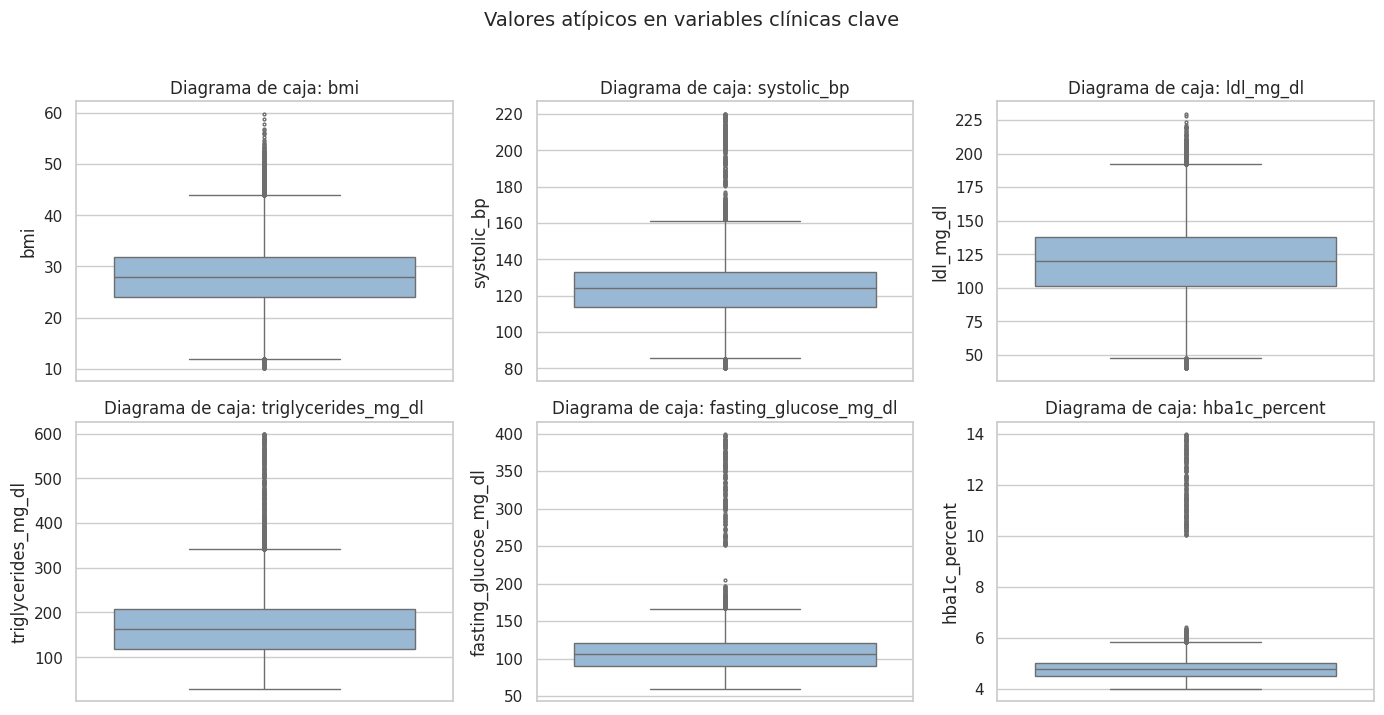

In [13]:
# ===== 2.5 Valores atípicos (outliers) con diagramas de caja =====
# Cuento los valores atípicos con la regla del rango intercuartílico (1,5·IQR) y los muestro con diagramas de caja; no los elimino.
num_cols_all = [c for c in df.select_dtypes(include="number").columns if c != "diabetes"]

def conteo_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum()

tabla_out = pd.DataFrame({"atípicos (regla 1.5·IQR)": {c: conteo_iqr(df[c].dropna()) for c in num_cols_all}})
tabla_out["% de filas"] = (tabla_out.iloc[:, 0] / len(df) * 100).round(2)
print("Variables con más valores atípicos:")
display(tabla_out.sort_values("% de filas", ascending=False).head(12))

vars_box = [c for c in ["bmi", "systolic_bp", "ldl_mg_dl", "triglycerides_mg_dl", "fasting_glucose_mg_dl", "hba1c_percent"] if c in df.columns]
fig, ejes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(ejes.ravel(), vars_box):
    sns.boxplot(y=df[c], ax=ax, color="#8FB8DE", fliersize=2)
    ax.set_title(f"Diagrama de caja: {c}")
    ax.set_ylabel(c)
plt.suptitle("Valores atípicos en variables clínicas clave", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

**Decisión sobre outliers:** **no los eliminé automáticamente.** En datos clínicos, un valor alto de glucosa o triglicéridos suele ser justamente la señal que distingue a una persona con diabetes; borrarlo me quitaría información valiosa y sesgaría el modelo hacia pacientes "normales". Solo anulé lo fisiológicamente imposible (paso 2.3). El escalado (`StandardScaler`) y los modelos que uso toleran razonablemente estos valores.

In [14]:
# ===== 2.6 Variables categóricas y codificación =====
# Reviso cuántas categorías tiene cada variable de texto para decidir cómo codificarla (One-Hot).
cat_cols_all = [c for c in df.select_dtypes(exclude="number").columns if c not in ID_COLS + ["diabetes_type"]]
card = pd.DataFrame({"categorías": df[cat_cols_all].nunique()}).sort_values("categorías", ascending=False)
print(f"{len(cat_cols_all)} variables categóricas. Las de mayor cardinalidad:")
display(card.head(10))
print("\nEjemplo de categorías:", {c: df[c].dropna().unique()[:4].tolist() for c in card.index[:3]})

87 variables categóricas. Las de mayor cardinalidad:


,categorías
ethnicity,8
race_group,8
occupation_category,8
region,8
state_province,8
diet_pattern,8
glucose_monitoring_frequency,7
country,7
education_level,6
climate_zone,6



Ejemplo de categorías: {'ethnicity': ['Black', 'White', 'Hispanic', 'Mixed'], 'race_group': ['Black', 'White', 'Hispanic', 'Mixed'], 'occupation_category': ['Professional', 'Unemployed', 'Technical', 'Service']}


**Codificación:** transformo las variables categóricas con **One-Hot Encoding** (una columna 0/1 por categoría) dentro de un `ColumnTransformer` en el Bloque 4. Elegí One-Hot y no números 1, 2, 3 porque las categorías (por ejemplo país o estado civil) **no tienen orden**; asignarles números haría creer al modelo que 3 > 1. Todas las variables de texto necesitan codificación (87 antes de excluir las de fuga); las traté como nominales por simplicidad, aunque algunas, como el nivel educativo, tienen cierto orden. Las categorías muy poco frecuentes (< 0,5 %) las agrupo en una sola para no generar columnas inútiles, y los identificadores los descarto.

### Separación de X (predictoras) y y (objetivo) – **fuga de información (data leakage)**
Este dataset contiene variables que **ya contienen la respuesta** o que solo existen *porque el paciente ya fue diagnosticado*: si un paciente toma metformina, usa insulina, tiene "diagnóstico previo de diabetes" o complicaciones diabéticas, ya sé que tiene diabetes. Si las incluyera obtendría métricas casi perfectas pero **inútiles** (el modelo no estaría prediciendo, solo leyendo la respuesta). Por eso las **excluí**.

Las pruebas de glucosa/HbA1c son diferentes: son criterios clínicos de diagnóstico, así que son muy predictivas pero no son "trampa" en sentido estricto. Las dejé controladas con un interruptor (`INCLUIR_PRUEBAS_GLUCEMIA`) para poder comparar ambos escenarios (ver el experimento adicional al final del Bloque 5).

In [15]:
# ===== 2.7 Definición de X e y =====
# Separo las variables predictoras (X) de la variable objetivo (y), excluyendo las que ya contienen el diagnóstico (fuga de información).
INCLUIR_PRUEBAS_GLUCEMIA = True   # True = uso glucosa y HbA1c | False = las excluyo (escenario más difícil y más honesto)

FUGA_DIAGNOSTICO = [   # ya contienen el diagnóstico o dependen de haber sido diagnosticado
    "diabetes_status", "diabetes_type", "previous_diabetes_diagnosis", "diabetes_medication",
    "metformin_use", "insulin_use", "sulfonylurea_use", "sglt2_inhibitor_use", "glp1_medication_use",
    "dpp4_inhibitor_use", "diabetes_risk_score", "diabetic_retinopathy", "diabetic_neuropathy",
    "diabetic_nephropathy", "diabetic_foot_problem", "diabetic_ketoacidosis_history",
    "diabetes_complication_count", "diabetes_education_received", "glucose_monitoring_frequency",
    "home_glucose_monitoring", "continuous_glucose_monitor", "hypoglycemia_history",
    "hyperglycemia_history", "medication_adherence_percent", "self_management_score",
    "cardiovascular_complication",
]
FUGA_COMPUESTAS = [    # variables "resumen" que cuentan o incorporan el propio diagnóstico (las detecté en la auditoría)
    "chronic_condition_count",   # número de condiciones crónicas: el conteo incluye la diabetes
]
PRUEBAS_GLUCEMIA = [
    "fasting_glucose_mg_dl", "random_glucose_mg_dl", "post_meal_glucose_mg_dl", "two_hour_glucose_mg_dl",
    "glucose_variability", "hba1c_percent", "estimated_average_glucose_mg_dl",
]

excluir = set(ID_COLS + ["diabetes", "diabetes_type", "diabetes_status"] + FUGA_DIAGNOSTICO + FUGA_COMPUESTAS)
if not INCLUIR_PRUEBAS_GLUCEMIA:
    excluir |= set(PRUEBAS_GLUCEMIA)
excluir = [c for c in df.columns if c in excluir]

X = df.drop(columns=excluir)
constantes = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
X = X.drop(columns=constantes)
bools = X.select_dtypes(include="bool").columns
X[bools] = X[bools].astype(int)
y = df["diabetes"]

print(f"Columnas excluidas ({len(excluir)}): ", excluir)
print(f"Columnas constantes eliminadas: {constantes if constantes else 'ninguna'}")
print(f"\nX: {X.shape[0]:,} filas × {X.shape[1]} variables predictoras "
      f"({X.select_dtypes(include='number').shape[1]} numéricas, {X.select_dtypes(exclude='number').shape[1]} categóricas)")
print(f"y: {y.shape[0]:,} valores | balance: {y.mean() * 100:.1f} % con diabetes")

Columnas excluidas (30):  ['patient_id', 'record_id', 'previous_diabetes_diagnosis', 'diabetes_medication', 'metformin_use', 'insulin_use', 'sulfonylurea_use', 'sglt2_inhibitor_use', 'glp1_medication_use', 'dpp4_inhibitor_use', 'medication_adherence_percent', 'glucose_monitoring_frequency', 'home_glucose_monitoring', 'continuous_glucose_monitor', 'diabetes_education_received', 'self_management_score', 'diabetic_retinopathy', 'diabetic_neuropathy', 'diabetic_nephropathy', 'diabetic_foot_problem', 'hypoglycemia_history', 'hyperglycemia_history', 'diabetic_ketoacidosis_history', 'cardiovascular_complication', 'diabetes_complication_count', 'diabetes_risk_score', 'chronic_condition_count', 'diabetes_status', 'diabetes_type', 'diabetes']
Columnas constantes eliminadas: ninguna

X: 99,958 filas × 179 variables predictoras (112 numéricas, 67 categóricas)
y: 99,958 valores | balance: 28.0 % con diabetes


### 2.8 Auditoría de fuga de información (poder predictivo de cada variable por sí sola)
Una señal de alarma clásica: **si un modelo sencillo logra métricas perfectas (100 %), casi seguro hay una variable que ya contiene la respuesta.** En mi primera ejecución de este notebook la regresión logística y la red neuronal dieron 100 % de accuracy; al revisar los coeficientes vi que la variable dominante era `chronic_condition_count` (número de condiciones crónicas) y que el modelo la combinaba con signo contrario a las demás enfermedades: en la práctica **restaba** hipertensión, hiperlipidemia, etc. del conteo y lo que sobraba era la diabetes. Esa variable ya tenía el diagnóstico "escondido" en el conteo, así que la **excluí**.

La siguiente celda automatiza esa revisión: mido cuánto predice **cada variable por sí sola** (AUC individual: 0,5 = no predice nada, 1,0 = predice perfecto) y marco las sospechosas. Con ella excluí además `overall_health_score` y `physical_health_score` (AUC individual de 0,89 y 0,86).

In [16]:
# ===== 2.8 Auditoría de fuga: AUC de cada variable por sí sola =====
# Mido cuánto predice cada variable por sí sola (AUC individual) y excluyo las que predicen casi perfecto.
from sklearn.metrics import roc_auc_score

UMBRAL_FUGA = 0.85     # una sola variable con AUC >= 0,85 (o <= 0,15) se considera sospechosa

def auc_individual(serie, objetivo):
    if pd.api.types.is_numeric_dtype(serie):
        s = serie.fillna(serie.median())
    else:                                                  # categórica: se reemplaza cada categoría por su % de diabetes
        s = serie.fillna("(nulo)").map(objetivo.groupby(serie.fillna("(nulo)")).mean())
    auc = roc_auc_score(objetivo, s)
    return max(auc, 1 - auc)                               # simétrico: 0,9 y 0,1 predicen igual de bien

poder = pd.Series({c: auc_individual(X[c], y) for c in X.columns}).sort_values(ascending=False)
print("Las 12 variables que más predicen la diabetes por sí solas:")
display(poder.head(12).round(3).to_frame("AUC individual"))

sospechosas = poder[poder >= UMBRAL_FUGA].index.tolist()
print(f"\nVariables con AUC >= {UMBRAL_FUGA}: {sospechosas if sospechosas else 'ninguna'}")
if sospechosas:
    X = X.drop(columns=sospechosas)
    print(f"→ Se excluyen de X por posible fuga. X queda con {X.shape[1]} variables.")

print("\nRevisión de puntajes compuestos (conviene mencionarlos en la sustentación):")
compuestas = [c for c in X.columns if c.endswith("_score") or c in ("overall_health_score",)]
display(poder.reindex([c for c in compuestas if c in poder.index]).round(3).to_frame("AUC individual"))

Las 12 variables que más predicen la diabetes por sí solas:


,AUC individual
overall_health_score,0.886
physical_health_score,0.861
fasting_glucose_mg_dl,0.758
insulin_resistance_index,0.738
kidney_risk_score,0.738
metabolic_risk_score,0.732
quality_of_life_score,0.729
cardiovascular_risk_score,0.727
hypertension_risk_score,0.725
mean_arterial_pressure,0.709



Variables con AUC >= 0.85: ['overall_health_score', 'physical_health_score']
→ Se excluyen de X por posible fuga. X queda con 177 variables.

Revisión de puntajes compuestos (conviene mencionarlos en la sustentación):


,AUC individual
diet_quality_score,0.610
healthcare_access_score,0.501
food_access_score,0.501
environmental_risk_score,0.502
walkability_score,0.501
cardiovascular_risk_score,0.727
metabolic_risk_score,0.732
obesity_risk_score,0.702
hypertension_risk_score,0.725
kidney_risk_score,0.738


In [17]:
# ===== 2.9 Consistencia clínica de las etiquetas (¿hay "sanos" con valores de diabetes?) =====
# Verifico si hay pacientes 'sin diabetes' con valores de laboratorio típicos de diabetes (posible ruido en las etiquetas).
sin_d = df[df["diabetes"] == 0]
if {"hba1c_percent", "fasting_glucose_mg_dl"} <= set(df.columns):
    print(f"Pacientes SIN diabetes con HbA1c >= 6,5 %:          {(sin_d['hba1c_percent'] >= 6.5).sum():,}")
    print(f"Pacientes SIN diabetes con glucosa en ayunas >= 126: {(sin_d['fasting_glucose_mg_dl'] >= 126).sum():,}")
    print(f"Pacientes SIN diabetes con HbA1c > 10 %:             {(sin_d['hba1c_percent'] > 10).sum():,}")
    con_d = df[df["diabetes"] == 1]
    print(f"\nPromedio de HbA1c en pacientes CON diabetes: {con_d['hba1c_percent'].mean():.2f} % "
          f"(en la práctica clínica suele ser > 6,5 %)")

Pacientes SIN diabetes con HbA1c >= 6,5 %:          146
Pacientes SIN diabetes con glucosa en ayunas >= 126: 6,012
Pacientes SIN diabetes con HbA1c > 10 %:             146

Promedio de HbA1c en pacientes CON diabetes: 4.97 % (en la práctica clínica suele ser > 6,5 %)


**Lectura:** los criterios clínicos habituales de diabetes son HbA1c ≥ 6,5 % o glucosa en ayunas ≥ 126 mg/dL. Encontré 146 pacientes "sin diabetes" con HbA1c mayor a 6,5 % (todos por encima de 10 %), 6.012 con glucosa en ayunas ≥ 126 y un promedio de HbA1c de solo 4,97 % en los pacientes "con diabetes". Esto me indica que el dataset es **sintético o tiene ruido en las etiquetas**, y lo tomo como una limitación importante en mi informe.

### 🧩 Reto del Bloque 2 – ¿Por qué el escalado se ajusta solo con entrenamiento?
El escalador calcula la **media y la desviación estándar** de cada variable. Si lo ajusto con **todo** el conjunto, esas estadísticas incluyen información de los datos de prueba: el modelo "se asoma" a datos que supuestamente no ha visto y las métricas salen **más optimistas que la realidad** (esto es *data leakage*). El conjunto de prueba debe simular pacientes **nuevos**: en la vida real, cuando llegue un paciente nuevo, solo contaré con la media y la desviación aprendidas con los datos históricos. Por eso hago `fit` solo con entrenamiento y luego aplico `transform` igual a entrenamiento y prueba. Lo mismo hago con la mediana y la moda de la imputación.

---
# Bloque 3. Análisis exploratorio y visualización

In [18]:
# ===== Preparación del EDA =====
# Preparo el análisis exploratorio: etiqueta legible para los grupos y lista de variables numéricas que voy a graficar.
df["grupo"] = df["diabetes"].map({0: "Sin diabetes", 1: "Con diabetes"})   # solo para graficar (no entra en X)
orden_grupos = ["Sin diabetes", "Con diabetes"]
vars_num = [c for c in ["age", "bmi", "waist_circumference_cm", "hba1c_percent", "fasting_glucose_mg_dl",
                        "systolic_bp", "ldl_mg_dl", "triglycerides_mg_dl"] if c in df.columns]
print("Variables numéricas usadas en el EDA:", vars_num)
display(df.groupby("grupo")[vars_num].mean().round(2).T)

Variables numéricas usadas en el EDA: ['age', 'bmi', 'waist_circumference_cm', 'hba1c_percent', 'fasting_glucose_mg_dl', 'systolic_bp', 'ldl_mg_dl', 'triglycerides_mg_dl']


grupo,Con diabetes,Sin diabetes
age,55.28,47.39
bmi,31.24,26.79
waist_circumference_cm,91.55,82.90
hba1c_percent,4.97,4.69
fasting_glucose_mg_dl,121.07,100.42
systolic_bp,130.75,120.93
ldl_mg_dl,124.35,118.05
triglycerides_mg_dl,185.65,155.94


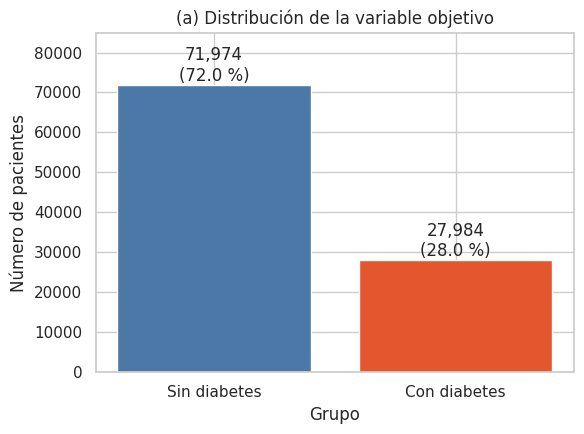

Tipos de diabetes dentro del grupo 'Con diabetes':


,pacientes
diabetes_type,
Type 2,25194
Other Diabetes,2174
Gestational Diabetes,108
Type 1,3


In [19]:
# ===== (a) Gráfico de barras: distribución de la variable objetivo =====
# Grafico cuántos pacientes hay en cada grupo y qué porcentaje representan.
conteo = df["grupo"].value_counts().reindex(orden_grupos)
fig, ax = plt.subplots(figsize=(6, 4.5))
barras = ax.bar(conteo.index, conteo.values, color=[COLORES[g] for g in conteo.index])
for b, v in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / conteo.sum() * 100:.1f} %)", ha="center", va="bottom")
ax.set_title("(a) Distribución de la variable objetivo")
ax.set_xlabel("Grupo"); ax.set_ylabel("Número de pacientes")
ax.set_ylim(0, conteo.max() * 1.18)
plt.tight_layout(); plt.show()

print("Tipos de diabetes dentro del grupo 'Con diabetes':")
display(df.loc[df["diabetes"] == 1, "diabetes_type"].value_counts().to_frame("pacientes"))

**(a) Distribución de la variable objetivo**

- **Patrón que observo:** hay 71.974 pacientes sin diabetes (72 %) y 27.984 con diabetes (28 %): las clases están desbalanceadas (razón 2,6 : 1).
- **Qué información me aporta:** me muestra que la accuracy sola engaña (un modelo que siempre dijera "sin diabetes" acertaría 72 %) y justifica que use `stratify`, `class_weight` y métricas como recall y F1.
- **Limitaciones:** dentro del grupo "con diabetes" casi todo es Tipo 2 (25.194); el Tipo 1 solo tiene 3 casos, así que el modelo no puede aprender nada específico de ese tipo.

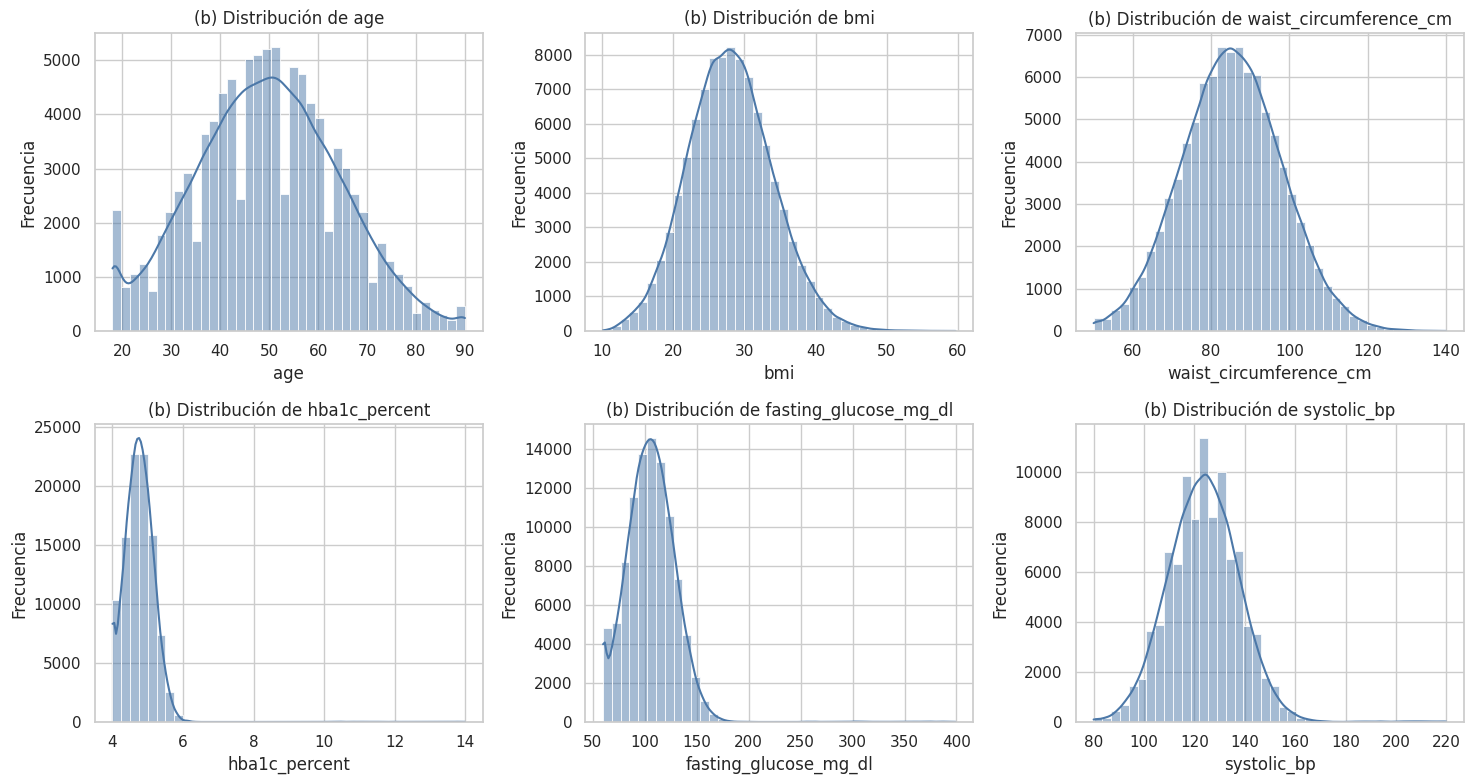

,mean,std,min,50%,max
age,49.60,14.73,18.0,50.00,90.00
bmi,28.04,5.95,10.1,27.88,59.69
waist_circumference_cm,85.32,12.74,50.0,85.20,140.00
hba1c_percent,4.77,0.51,4.0,4.75,13.99
fasting_glucose_mg_dl,106.20,24.34,60.0,105.60,399.04
systolic_bp,123.68,14.17,80.0,124.00,219.86


,asimetría
age,0.08
bmi,0.21
waist_circumference_cm,0.06
hba1c_percent,6.21
fasting_glucose_mg_dl,1.81
systolic_bp,0.34


In [20]:
# ===== (b) Histogramas de variables numéricas relevantes =====
# Grafico histogramas (con curva de densidad) de seis variables numéricas y calculo estadísticas descriptivas y asimetría.
fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(ejes.ravel(), vars_num[:6]):
    sns.histplot(df[c].dropna(), bins=40, kde=True, ax=ax, color="#4C78A8")
    ax.set_title(f"(b) Distribución de {c}")
    ax.set_xlabel(c); ax.set_ylabel("Frecuencia")
plt.tight_layout(); plt.show()
display(df[vars_num[:6]].describe().round(2).T[["mean", "std", "min", "50%", "max"]])
display(df[vars_num[:6]].skew().round(2).to_frame("asimetría"))

**(b) Histogramas**

- **Patrón que observo:** edad, IMC, cintura y presión sistólica tienen forma de campana, casi simétricas (asimetría entre 0,06 y 0,34). La glucosa en ayunas (asimetría 1,81) y sobre todo la HbA1c (6,21) tienen cola larga a la derecha: la mayoría está en valores bajos y unos pocos llegan a 250–400 mg/dL (glucosa) o 10–14 % (HbA1c).
- **Qué información me aporta:** me indica qué variables tienen valores extremos y justifica el escalado y el uso de la mediana al imputar.
- **Limitaciones:** mezcla pacientes con y sin diabetes, así que no muestra cómo se distribuye cada grupo por separado. Además, la HbA1c, con media de solo 4,77 %, no se parece a la de una población real con 28 % de diabetes.

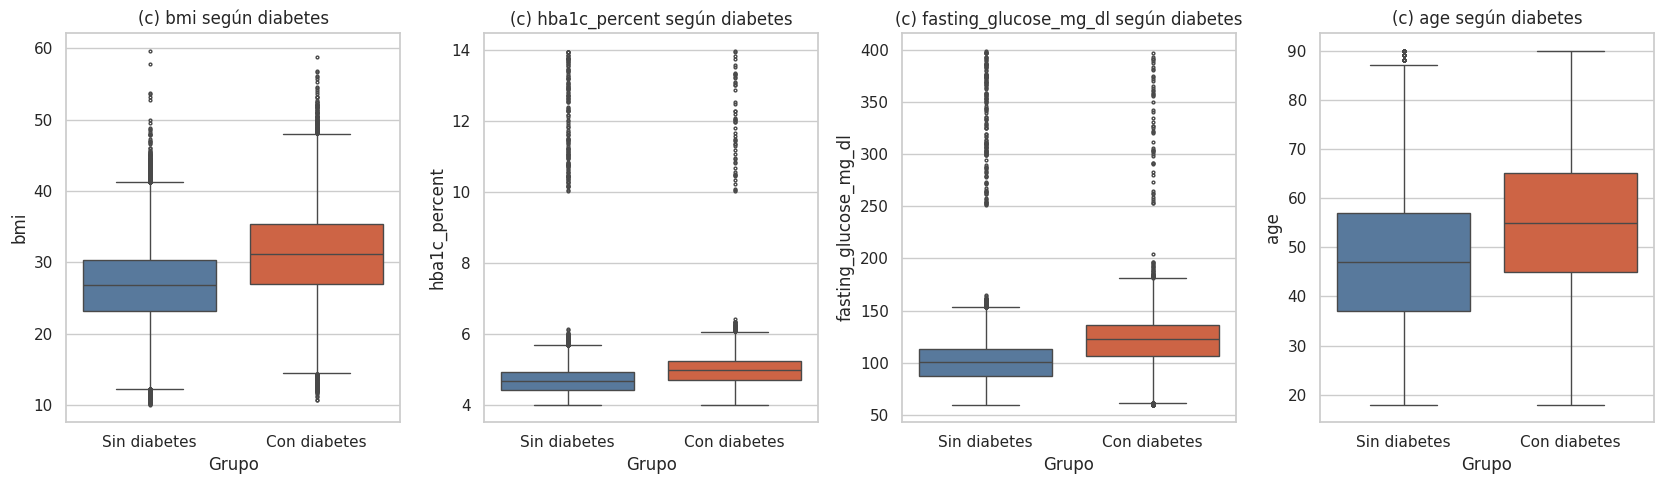

grupo,Con diabetes,Sin diabetes
bmi,31.25,26.79
hba1c_percent,4.97,4.67
fasting_glucose_mg_dl,122.70,100.50
age,55.00,47.00


In [21]:
# ===== (c) Diagramas de caja: variable numérica según grupo =====
# Comparo con diagramas de caja cuatro variables numéricas entre los pacientes con y sin diabetes.
vars_c = [c for c in ["bmi", "hba1c_percent", "fasting_glucose_mg_dl", "age"] if c in df.columns]
fig, ejes = plt.subplots(1, len(vars_c), figsize=(4.2 * len(vars_c), 5))
for ax, c in zip(np.atleast_1d(ejes), vars_c):
    sns.boxplot(data=df, x="grupo", y=c, order=orden_grupos, palette=COLORES, ax=ax, fliersize=2)
    ax.set_title(f"(c) {c} según diabetes")
    ax.set_xlabel("Grupo"); ax.set_ylabel(c)
plt.tight_layout(); plt.show()
display(df.groupby("grupo")[vars_c].median().round(2).T)

**(c) Diagramas de caja por grupo**

- **Patrón que observo:** los pacientes con diabetes tienen medianas más altas: IMC 31,3 vs 26,8; glucosa 122,7 vs 100,5; edad 55 vs 47; HbA1c 4,97 vs 4,67. Aun así las cajas se traslapan bastante.
- **Qué información me aporta:** me confirma que el IMC, la glucosa y la edad se asocian con la diabetes, pero que ninguna variable separa sola a los grupos.
- **Limitaciones:** en HbA1c y glucosa aparecen puntos extremos (HbA1c de 10 a 14, glucosa de 250 a 400) en **ambos** grupos por igual, incluso en pacientes "sin diabetes"; eso no tiene sentido clínico y me sugiere ruido en el dataset.

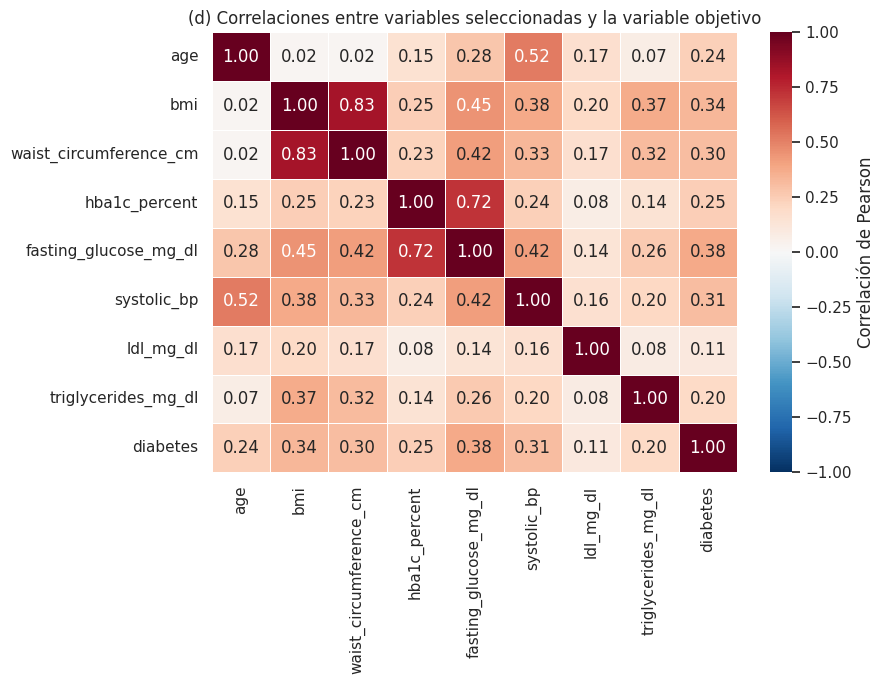

Correlación de cada variable con la variable objetivo (de mayor a menor):


,correlación
fasting_glucose_mg_dl,0.381
bmi,0.336
systolic_bp,0.311
waist_circumference_cm,0.305
hba1c_percent,0.249
age,0.241
triglycerides_mg_dl,0.201
ldl_mg_dl,0.106


In [22]:
# ===== (d) Mapa de calor de correlaciones =====
# Calculo y grafico las correlaciones entre variables seleccionadas y la variable objetivo.
cols_corr = vars_num + ["diabetes"]
corr = df[cols_corr].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label": "Correlación de Pearson"})
plt.title("(d) Correlaciones entre variables seleccionadas y la variable objetivo")
plt.tight_layout(); plt.show()
print("Correlación de cada variable con la variable objetivo (de mayor a menor):")
display(corr["diabetes"].drop("diabetes").sort_values(key=np.abs, ascending=False).round(3).to_frame("correlación"))

**(d) Mapa de calor de correlaciones**

- **Patrón que observo:** las correlaciones con la diabetes son moderadas: glucosa 0,38, IMC 0,34, presión sistólica 0,31, cintura 0,30, HbA1c 0,25, edad 0,24, triglicéridos 0,20 y LDL 0,11. Hay variables muy correlacionadas entre sí: IMC–cintura 0,83 y HbA1c–glucosa 0,72; la edad se relaciona con la presión sistólica (0,52).
- **Qué información me aporta:** veo que ninguna variable es un predictor fuerte por sí sola, así que hace falta combinarlas. La alta correlación entre variables indica información redundante (multicolinealidad), que afecta la interpretación de los coeficientes de la regresión.
- **Limitaciones:** Pearson solo mide relaciones lineales y correlación no es causalidad; además, solo incluí 8 de las más de 100 variables numéricas.

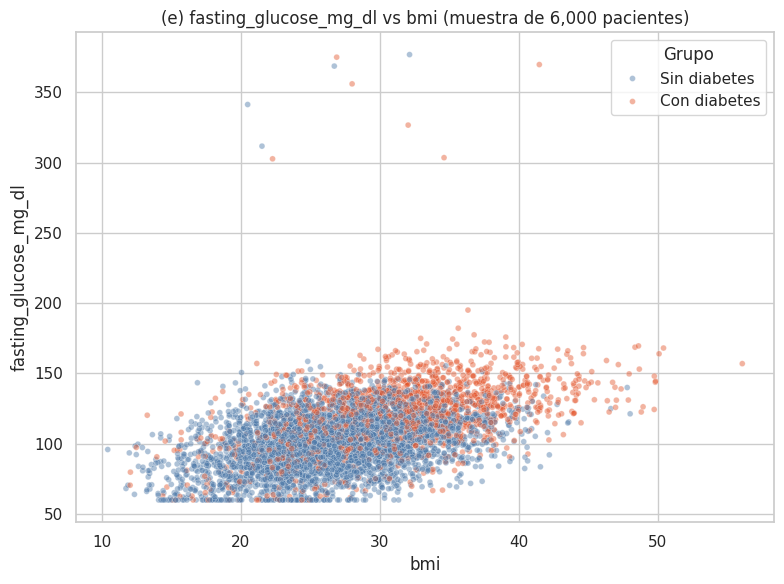

In [23]:
# ===== (e) Dispersión entre dos variables, diferenciando por grupo =====
# Grafico glucosa vs IMC (en una muestra de 6.000 pacientes para que se vea bien), diferenciando por grupo.
vx, vy = ("bmi", "fasting_glucose_mg_dl") if {"bmi", "fasting_glucose_mg_dl"} <= set(df.columns) else vars_num[:2]
muestra = df.sample(min(6000, len(df)), random_state=SEED)      # muestra para que el gráfico sea legible
plt.figure(figsize=(8, 6))
sns.scatterplot(data=muestra, x=vx, y=vy, hue="grupo", hue_order=orden_grupos, palette=COLORES, alpha=0.45, s=18)
plt.title(f"(e) {vy} vs {vx} (muestra de {len(muestra):,} pacientes)")
plt.xlabel(vx); plt.ylabel(vy); plt.legend(title="Grupo")
plt.tight_layout(); plt.show()

**(e) Dispersión glucosa vs IMC**

- **Patrón que observo:** los pacientes con diabetes (naranja) se concentran arriba y a la derecha (IMC alto y glucosa alta), pero hay mucho traslape con los pacientes sin diabetes (azul). Se ven unos pocos puntos aislados con glucosa de 300–375.
- **Qué información me aporta:** me muestra visualmente que la combinación de dos variables separa mejor que cada una por separado, pero no de forma perfecta; por eso necesito modelos multivariables.
- **Limitaciones:** grafiqué una muestra de 6.000 pacientes y solo dos variables a la vez; el traslape depende de las demás variables, que no se ven en este gráfico.

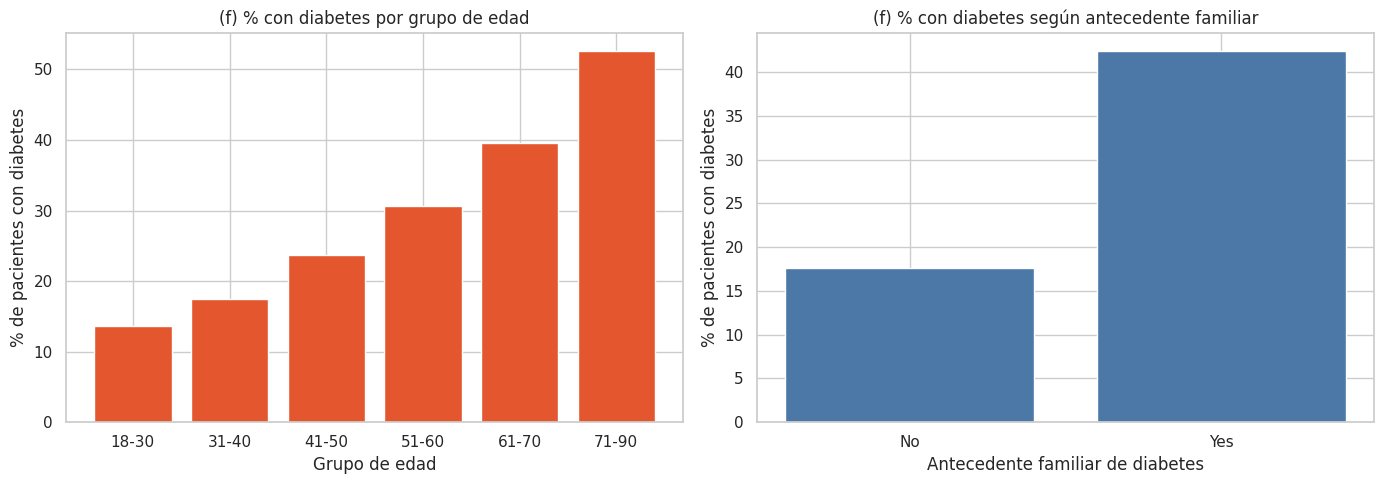

In [24]:
# ===== (f) Gráfico adicional: prevalencia de diabetes por grupo de edad y por antecedente familiar =====
# Gráfico adicional que elegí: porcentaje de pacientes con diabetes por grupo de edad y por antecedente familiar.
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

if "age_group" in df.columns:
    prev_edad = df.groupby("age_group")["diabetes"].mean().mul(100)
    prev_edad = prev_edad.reindex(sorted(prev_edad.index, key=lambda s: int("".join(ch for ch in str(s).split("-")[0] if ch.isdigit()) or 0)))
    ejes[0].bar(prev_edad.index.astype(str), prev_edad.values, color="#E4572E")
    ejes[0].set_title("(f) % con diabetes por grupo de edad")
    ejes[0].set_xlabel("Grupo de edad"); ejes[0].set_ylabel("% de pacientes con diabetes")

if "family_history_diabetes" in df.columns:
    prev_fam = df.groupby("family_history_diabetes")["diabetes"].mean().mul(100)
    ejes[1].bar(prev_fam.index.astype(str), prev_fam.values, color="#4C78A8")
    ejes[1].set_title("(f) % con diabetes según antecedente familiar")
    ejes[1].set_xlabel("Antecedente familiar de diabetes"); ejes[1].set_ylabel("% de pacientes con diabetes")
plt.tight_layout(); plt.show()

**(f) Prevalencia por edad y antecedente familiar**

- **Patrón que observo:** el porcentaje con diabetes aumenta de forma casi lineal con la edad: aprox. 14 % en el grupo de 18–30 años hasta aprox. 53 % en el de 71–90. Con antecedente familiar es aprox. 42 %, frente a aprox. 18 % sin antecedente.
- **Qué información me aporta:** me muestra que la edad y el antecedente familiar son factores de riesgo claros y fáciles de explicar.
- **Limitaciones:** son datos observacionales: muestran asociación, no causa, y los grupos de edad son rangos amplios.

### 🧩 Reto del Bloque 3 – Desbalance de la variable objetivo

In [25]:
# ===== Reto Bloque 3: desbalance de clases =====
# Calculo la proporción de cada clase y cuánto valdría la accuracy de un modelo que siempre responda 'sin diabetes'.
prop = y.value_counts(normalize=True).sort_index()
print(f"Sin diabetes: {prop[0] * 100:.1f} % | Con diabetes: {prop[1] * 100:.1f} %")
print(f"Razón de desbalance: {prop[0] / prop[1]:.2f} : 1")
print(f"\nUn 'modelo' que siempre responda 'sin diabetes' tendría una accuracy de {prop[0] * 100:.1f} % "
      f"y un recall de 0 % para los enfermos.")

Sin diabetes: 72.0 % | Con diabetes: 28.0 %
Razón de desbalance: 2.57 : 1

Un 'modelo' que siempre responda 'sin diabetes' tendría una accuracy de 72.0 % y un recall de 0 % para los enfermos.


**Respuesta:** la variable objetivo está desbalanceada: el 72,0 % de los pacientes no tiene diabetes (71.974) y el 28,0 % sí la tiene (27.984), una razón de 2,57 a 1. Esto afecta la evaluación porque la accuracy puede parecer buena sin que el modelo detecte realmente a los enfermos: un modelo que siempre respondiera "sin diabetes" tendría 72 % de accuracy y 0 % de recall para la clase con diabetes. Por eso no uso solo la accuracy, sino también precision, recall, F1, AUC-ROC y la matriz de confusión. Para reducir el efecto del desbalance dividí los datos con `stratify=y`, que mantiene el 28 % de positivos tanto en entrenamiento como en prueba, y usé `class_weight="balanced"` (y pesos de clase en la red neuronal) para penalizar más los errores en la clase minoritaria.

---
# Bloque 4. Modelos de clasificación
Modelo A: **Regresión logística** · Modelo B: **Árbol de decisión**

In [26]:
# ===== 4.1 División entrenamiento / prueba (80/20, estratificada, con semilla) =====
# Divido en entrenamiento (80 %) y prueba (20 %) con estratificación y semilla, y armo el preprocesamiento (imputar, escalar y One-Hot), ajustándolo SOLO con entrenamiento.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)
print(f"Entrenamiento: {X_train.shape[0]:,} filas ({y_train.mean() * 100:.1f} % con diabetes)")
print(f"Prueba:        {X_test.shape[0]:,} filas ({y_test.mean() * 100:.1f} % con diabetes)")

# ===== 4.2 Preprocesamiento: se AJUSTA solo con entrenamiento =====
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

preprocesador = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("escalar", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                               min_frequency=0.005, sparse_output=False))]), cat_cols),
])
Xtr = preprocesador.fit_transform(X_train).astype("float32")   # fit SOLO con entrenamiento
Xte = preprocesador.transform(X_test).astype("float32")        # a prueba solo se le aplica transform
nombres_vars = preprocesador.get_feature_names_out()
print(f"\nVariables numéricas: {len(num_cols)} | categóricas: {len(cat_cols)}")
print(f"Matriz final de entrada al modelo: {Xtr.shape[1]} columnas (después del One-Hot)")
print("Valores nulos tras el preprocesamiento:", int(np.isnan(Xtr).sum() + np.isnan(Xte).sum()))

Entrenamiento: 79,966 filas (28.0 % con diabetes)
Prueba:        19,992 filas (28.0 % con diabetes)

Variables numéricas: 110 | categóricas: 67
Matriz final de entrada al modelo: 366 columnas (después del One-Hot)
Valores nulos tras el preprocesamiento: 0


In [27]:
# ===== 4.3 Entrenamiento de ambos modelos =====
# Entreno la regresión logística (modelo A) y el árbol de decisión (modelo B) con pesos de clase balanceados.
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

modelo_lr = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
modelo_arbol = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced", random_state=SEED)

modelo_lr.fit(Xtr, y_train)
modelo_arbol.fit(Xtr, y_train)
print("Modelos entrenados.")

Modelos entrenados.


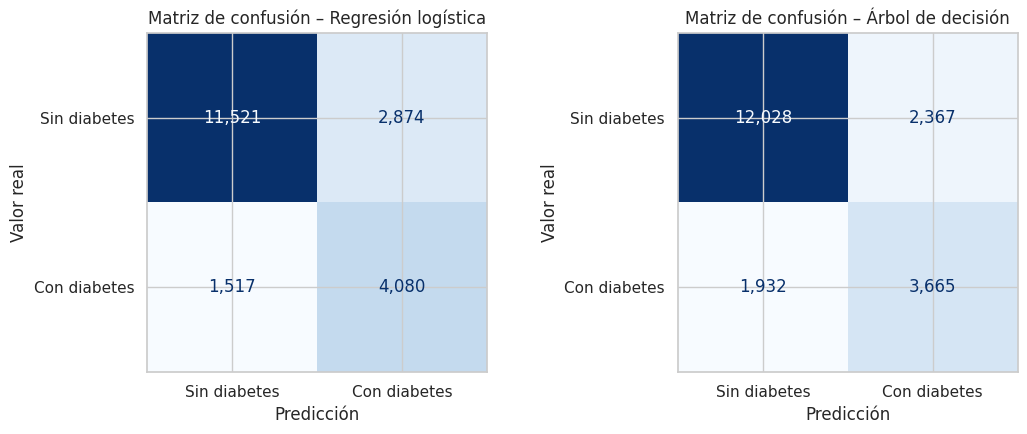

Comparación (conjunto de PRUEBA):


,Accuracy,Precision,Recall,F1,AUC-ROC
Regresión logística,0.7804,0.5867,0.7290,0.6501,0.8423
Árbol de decisión,0.7850,0.6076,0.6548,0.6303,0.8167


In [28]:
# ===== 4.4 Métricas y matrices de confusión =====
# Calculo accuracy, precision, recall, F1 y AUC de ambos modelos en el conjunto de prueba y muestro sus matrices de confusión.
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

resultados = {}
def evaluar(nombre, y_real, y_pred, y_proba):
    resultados[nombre] = {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred),
        "Recall": recall_score(y_real, y_pred),
        "F1": f1_score(y_real, y_pred),
        "AUC-ROC": roc_auc_score(y_real, y_proba),
    }

proba_lr = modelo_lr.predict_proba(Xte)[:, 1];       pred_lr = (proba_lr >= 0.5).astype(int)
proba_arbol = modelo_arbol.predict_proba(Xte)[:, 1]; pred_arbol = (proba_arbol >= 0.5).astype(int)
evaluar("Regresión logística", y_test, pred_lr, proba_lr)
evaluar("Árbol de decisión", y_test, pred_arbol, proba_arbol)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (titulo, pred) in zip(ejes, [("Regresión logística", pred_lr), ("Árbol de decisión", pred_arbol)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Sin diabetes", "Con diabetes"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",d")
    ax.set_title(f"Matriz de confusión – {titulo}")
    ax.set_xlabel("Predicción"); ax.set_ylabel("Valor real")
plt.tight_layout(); plt.show()

tabla = pd.DataFrame(resultados).T.round(4)
print("Comparación (conjunto de PRUEBA):")
display(tabla)

if tabla["Accuracy"].max() >= 0.98:
    print("\n⚠️ ALERTA: un modelo tan simple no debería acertar ~100 %. Revisa la sección 2.8: casi seguro hay una "
          "variable que ya contiene el diagnóstico (fuga de información).")

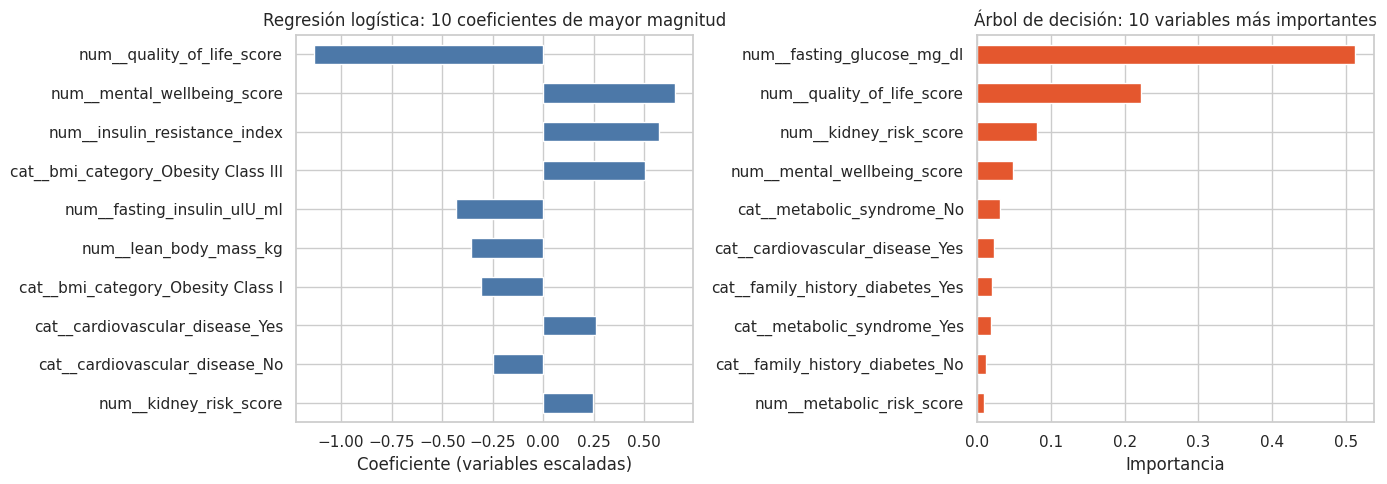

In [29]:
# ===== Variables más influyentes (útil para interpretar y para la sustentación) =====
# Miro qué variables pesan más en cada modelo para poder interpretar y explicar los resultados.
imp_lr = pd.Series(modelo_lr.coef_[0], index=nombres_vars).sort_values(key=np.abs, ascending=False).head(10)
imp_ar = pd.Series(modelo_arbol.feature_importances_, index=nombres_vars).sort_values(ascending=False).head(10)

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
imp_lr[::-1].plot.barh(ax=ejes[0], color="#4C78A8")
ejes[0].set_title("Regresión logística: 10 coeficientes de mayor magnitud"); ejes[0].set_xlabel("Coeficiente (variables escaladas)")
imp_ar[::-1].plot.barh(ax=ejes[1], color="#E4572E")
ejes[1].set_title("Árbol de decisión: 10 variables más importantes"); ejes[1].set_xlabel("Importancia")
plt.tight_layout(); plt.show()

### 🧩 Reto del Bloque 4 – ¿Qué modelo es el más adecuado?
**Modelo elegido: regresión logística.** Entre los dos modelos tradicionales elegí la regresión logística. El árbol de decisión tiene una accuracy (0,785) y una precision (0,608) ligeramente mayores que las de la regresión (0,780 y 0,587), pero esas no son las métricas que más importan en este caso. Como se trata de detectar pacientes con diabetes, lo más costoso es dejar enfermos sin detectar (falsos negativos), así que me guié por el **recall**: la regresión logística obtuvo 0,729 frente a 0,655 del árbol; detectó 4.080 de los 5.597 pacientes con diabetes del conjunto de prueba, contra 3.665 del árbol (415 más). También tuvo mejor F1 (0,650 frente a 0,630) y mejor AUC-ROC (0,842 frente a 0,817), lo que indica que separa mejor a los dos grupos en general. El costo es que genera más falsas alarmas (2.874 pacientes sanos clasificados como enfermos, frente a 2.367 del árbol). En el Bloque 5 comparo estos dos modelos con la red neuronal.

---
# Bloque 5. Red neuronal artificial (TensorFlow/Keras)
Mismas variables predictoras, misma división entrenamiento/prueba y mismo preprocesamiento del Bloque 4.

In [30]:
# ===== 5.1 Construcción de la red =====
# Construyo la red neuronal: entrada con una neurona por variable, capas ocultas de 16 y 8 neuronas con ReLU y salida sigmoide.
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(SEED)
n_entradas = Xtr.shape[1]

red = keras.Sequential([
    layers.Input(shape=(n_entradas,)),          # capa de entrada: una neurona por variable (ya codificada)
    layers.Dense(16, activation="relu"),        # oculta 1: 16 neuronas, ReLU
    layers.Dense(8, activation="relu"),         # oculta 2: 8 neuronas, ReLU
    layers.Dense(1, activation="sigmoid"),      # salida: probabilidad de tener diabetes (clasificación binaria)
], name="red_diabetes")

red.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),   # Adam: optimizador adaptativo estándar
            loss="binary_crossentropy",                            # pérdida estándar para clasificación binaria
            metrics=["accuracy"])
red.summary()

Model: "red_diabetes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │         5,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,017 (23.50 KB)

 Trainable params: 6,017 (23.50 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
# ===== 5.2 Entrenamiento (máximo 100 épocas) =====
# Entreno con un máximo de 100 épocas; uso EarlyStopping para detenerme cuando la validación deja de mejorar.
n0, n1 = np.bincount(y_train)
peso_clases = {0: len(y_train) / (2 * n0), 1: len(y_train) / (2 * n1)}   # compensa el desbalance
print("Pesos por clase:", {k: round(v, 3) for k, v in peso_clases.items()})

parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

historia = red.fit(
    Xtr, y_train.values.astype("float32"),
    validation_split=0.20,          # reservo el 20 % del entrenamiento para validar (NO toco la prueba)
    epochs=100, batch_size=256,
    class_weight=peso_clases,
    callbacks=[parada],
    verbose=2,
)
print(f"\nÉpocas realmente entrenadas: {len(historia.history['loss'])} (máximo permitido: 100)")

Pesos por clase: {0: np.float64(0.694), 1: np.float64(1.786)}
Epoch 1/100
250/250 - 2s - 9ms/step - accuracy: 0.7735 - loss: 0.5255 - val_accuracy: 0.8151 - val_loss: 0.4507
Epoch 2/100
250/250 - 1s - 4ms/step - accuracy: 0.8140 - loss: 0.4760 - val_accuracy: 0.8201 - val_loss: 0.4383
Epoch 3/100
250/250 - 1s - 4ms/step - accuracy: 0.8189 - loss: 0.4616 - val_accuracy: 0.8211 - val_loss: 0.4354
Epoch 4/100
250/250 - 1s - 4ms/step - accuracy: 0.8216 - loss: 0.4551 - val_accuracy: 0.8224 - val_loss: 0.4334
Epoch 5/100
250/250 - 1s - 4ms/step - accuracy: 0.8216 - loss: 0.4512 - val_accuracy: 0.8219 - val_loss: 0.4317
Epoch 6/100
250/250 - 2s - 8ms/step - accuracy: 0.8226 - loss: 0.4479 - val_accuracy: 0.8196 - val_loss: 0.4319
Epoch 7/100
250/250 - 1s - 5ms/step - accuracy: 0.8230 - loss: 0.4452 - val_accuracy: 0.8186 - val_loss: 0.4307
Epoch 8/100
250/250 - 2s - 9ms/step - accuracy: 0.8231 - loss: 0.4427 - val_accuracy: 0.8174 - val_loss: 0.4307
Epoch 9/100
250/250 - 1s - 4ms/step - accu

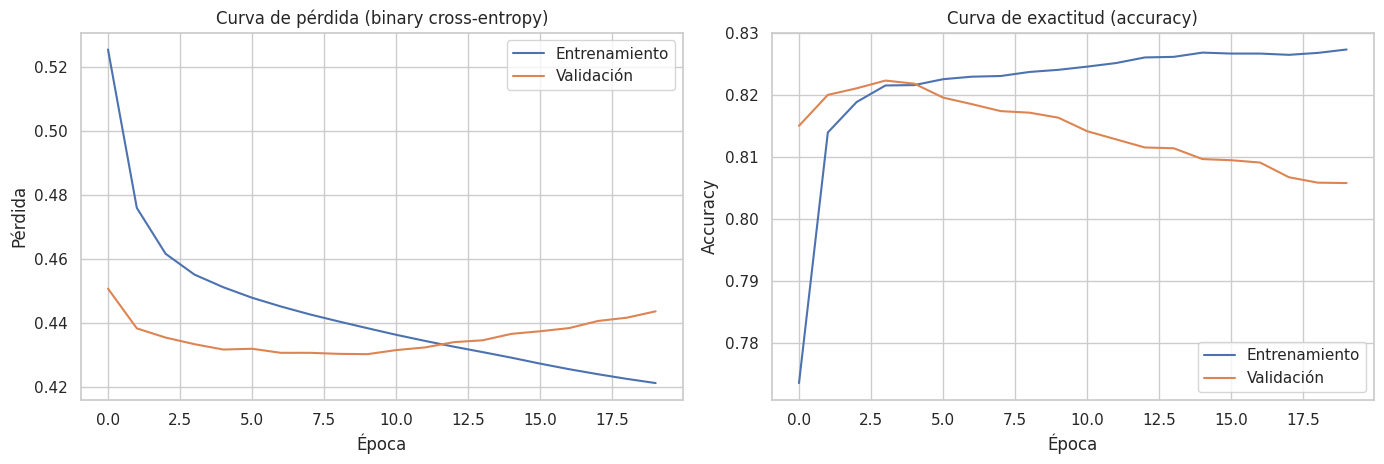

Mejor época (menor pérdida de validación): 10
Pérdida entrenamiento: 0.4212 | validación: 0.4437 | brecha: +0.0224
Accuracy entrenamiento: 0.8274 | validación: 0.8058


In [32]:
# ===== 5.3 Curvas de pérdida y exactitud =====
# Grafico las curvas de pérdida y de accuracy de entrenamiento y validación para revisar si hay sobreajuste.
h = historia.history
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8))
ejes[0].plot(h["loss"], label="Entrenamiento"); ejes[0].plot(h["val_loss"], label="Validación")
ejes[0].set_title("Curva de pérdida (binary cross-entropy)"); ejes[0].set_xlabel("Época"); ejes[0].set_ylabel("Pérdida"); ejes[0].legend()
ejes[1].plot(h["accuracy"], label="Entrenamiento"); ejes[1].plot(h["val_accuracy"], label="Validación")
ejes[1].set_title("Curva de exactitud (accuracy)"); ejes[1].set_xlabel("Época"); ejes[1].set_ylabel("Accuracy"); ejes[1].legend()
plt.tight_layout(); plt.show()

mejor = int(np.argmin(h["val_loss"]))
print(f"Mejor época (menor pérdida de validación): {mejor + 1}")
print(f"Pérdida entrenamiento: {h['loss'][-1]:.4f} | validación: {h['val_loss'][-1]:.4f} | brecha: {h['val_loss'][-1] - h['loss'][-1]:+.4f}")
print(f"Accuracy entrenamiento: {h['accuracy'][-1]:.4f} | validación: {h['val_accuracy'][-1]:.4f}")

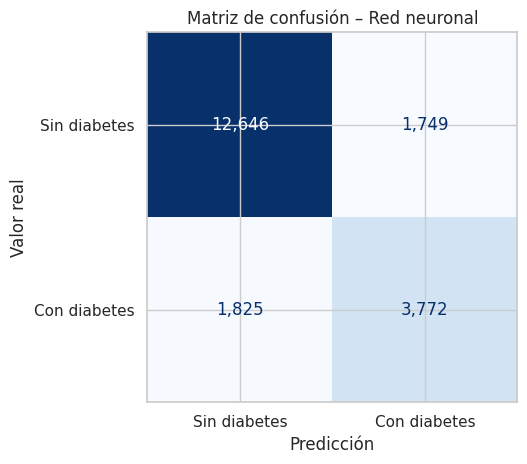

Comparación final de los tres modelos (conjunto de PRUEBA):


,Accuracy,Precision,Recall,F1,AUC-ROC
Regresión logística,0.7804,0.5867,0.7290,0.6501,0.8423
Árbol de decisión,0.7850,0.6076,0.6548,0.6303,0.8167
Red neuronal,0.8212,0.6832,0.6739,0.6785,0.8463


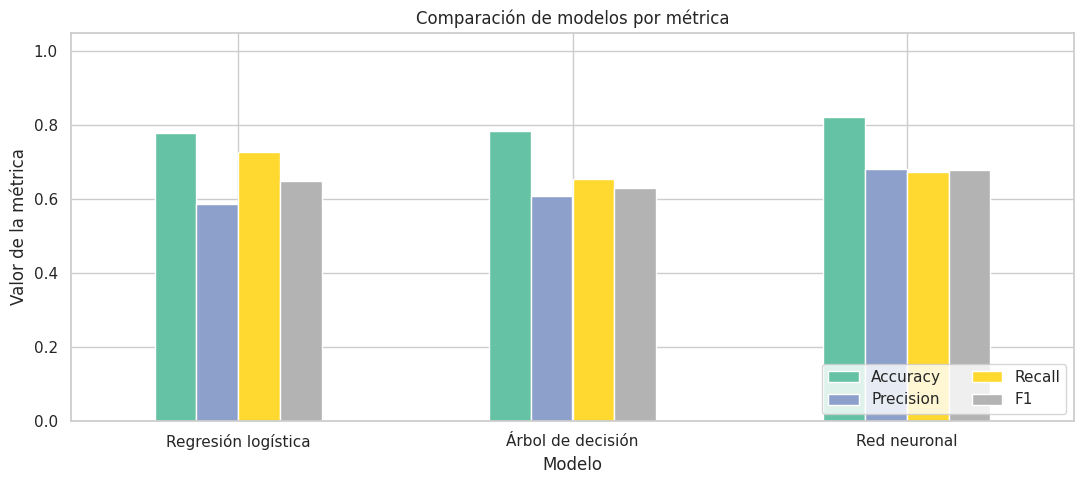

In [33]:
# ===== 5.4 Evaluación en el conjunto de PRUEBA y comparación con los otros dos modelos =====
# Evalúo la red en el conjunto de prueba (que no usé para entrenar) y la comparo con la regresión logística y el árbol.
proba_nn = red.predict(Xte, verbose=0).ravel()
pred_nn = (proba_nn >= 0.5).astype(int)
evaluar("Red neuronal", y_test, pred_nn, proba_nn)

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_nn), display_labels=["Sin diabetes", "Con diabetes"]).plot(
    cmap="Blues", colorbar=False, values_format=",d")
plt.title("Matriz de confusión – Red neuronal"); plt.xlabel("Predicción"); plt.ylabel("Valor real")
plt.tight_layout(); plt.show()

tabla = pd.DataFrame(resultados).T.round(4)
print("Comparación final de los tres modelos (conjunto de PRUEBA):")
display(tabla)

tabla.drop(columns="AUC-ROC").plot.bar(figsize=(11, 5), rot=0, colormap="Set2")
plt.title("Comparación de modelos por métrica"); plt.xlabel("Modelo"); plt.ylabel("Valor de la métrica")
plt.ylim(0, 1.05); plt.legend(loc="lower right", ncol=2); plt.tight_layout(); plt.show()

### 🧩 Reto del Bloque 5 – Sobreajuste, subajuste y una mejora
**Observación de las curvas:** veo señales de **sobreajuste leve**. La pérdida de entrenamiento baja de forma continua (de aproximadamente 0,53 a 0,42), pero la pérdida de validación llega a su mínimo cerca de la época 10 (alrededor de 0,43) y después empieza a subir (hasta cerca de 0,44). Pasa lo mismo con la accuracy: la de validación alcanza su máximo (cerca de 0,82) alrededor de la época 4 y luego baja a cerca de 0,81, mientras que la de entrenamiento sigue subiendo (cerca de 0,83). Esa separación creciente significa que la red empieza a memorizar los datos de entrenamiento y a generalizar peor. No veo subajuste, porque la red sí aprende: la pérdida de entrenamiento baja y la accuracy supera 0,80. El `EarlyStopping` detuvo el entrenamiento en la época 20 y restauró los pesos de la mejor época (la 10), así que la evaluación en el conjunto de prueba usa el mejor modelo y no el sobreajustado.

**Mejora propuesta:** agregaría regularización con capas `Dropout(0.3)` entre las capas ocultas (o regularización L2) para reducir la memorización. Además reduciría variables redundantes (por ejemplo, el IMC y la cintura tienen correlación de 0,83), probaría una tasa de aprendizaje menor y ajustaría el número de neuronas.

### Pregunta de nivel alto (+10 pts) – Accuracy del 90 % con recall del 40 %
*Supongamos que el modelo obtiene un accuracy del 90 %, pero detecta correctamente solo el 40 % de los casos positivos.*

Primero **demuestro con código** el efecto del umbral de decisión y elijo el umbral **sin mirar el conjunto de prueba** (uso predicciones de validación cruzada sobre el entrenamiento).

Umbral elegido con validación cruzada (recall objetivo 80%): 0.395


,Umbral 0.5,Umbral 0.39
Recall,0.7290,0.7986
Precision,0.5867,0.5015
F1,0.6501,0.6161
Accuracy,0.7804,0.7213


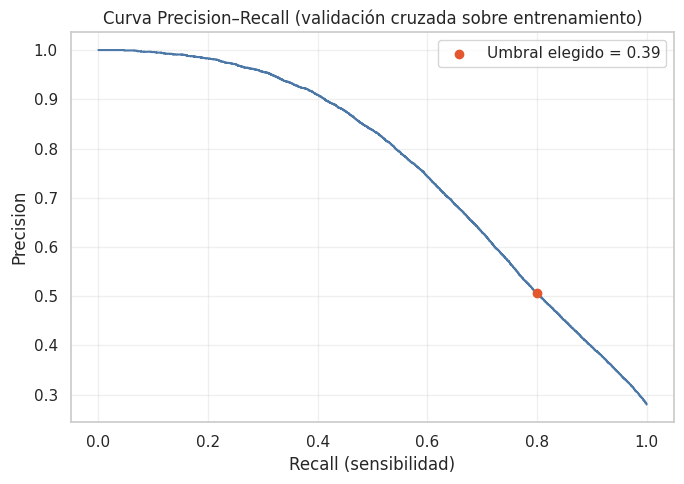

Average precision (área bajo la curva PR): 0.761


In [34]:
# ===== Reto nivel alto: ajuste del umbral SIN usar la prueba para elegirlo =====
# Demuestro cómo cambia el recall al mover el umbral de decisión, eligiéndolo SIN mirar el conjunto de prueba.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score

# 1) Calculo probabilidades "fuera de muestra" sobre el ENTRENAMIENTO (validación cruzada de 3 pliegues)
proba_cv = cross_val_predict(LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
                             Xtr, y_train, cv=3, method="predict_proba", n_jobs=-1)[:, 1]

# 2) Elijo el umbral MÁS ALTO que aún alcance el recall objetivo (así maximizo la precisión)
RECALL_OBJETIVO = 0.80
prec, rec, umbrales = precision_recall_curve(y_train, proba_cv)
ok = np.where(rec[:-1] >= RECALL_OBJETIVO)[0]
umbral = float(umbrales[ok[-1]]) if len(ok) else 0.5
print(f"Umbral elegido con validación cruzada (recall objetivo {RECALL_OBJETIVO:.0%}): {umbral:.3f}")

# 3) Evalúo UNA sola vez en la prueba
pred_umbral = (proba_lr >= umbral).astype(int)
comparacion = pd.DataFrame({
    "Umbral 0.5": [recall_score(y_test, pred_lr), precision_score(y_test, pred_lr), f1_score(y_test, pred_lr), accuracy_score(y_test, pred_lr)],
    f"Umbral {umbral:.2f}": [recall_score(y_test, pred_umbral), precision_score(y_test, pred_umbral), f1_score(y_test, pred_umbral), accuracy_score(y_test, pred_umbral)],
}, index=["Recall", "Precision", "F1", "Accuracy"]).round(4)
display(comparacion)

plt.figure(figsize=(7, 5))
plt.plot(rec, prec, color="#4C78A8")
plt.scatter(rec[ok[-1]] if len(ok) else 0, prec[ok[-1]] if len(ok) else 0, color="#E4572E", zorder=3, label=f"Umbral elegido = {umbral:.2f}")
plt.title("Curva Precision–Recall (validación cruzada sobre entrenamiento)")
plt.xlabel("Recall (sensibilidad)"); plt.ylabel("Precision"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"Average precision (área bajo la curva PR): {average_precision_score(y_train, proba_cv):.3f}")

**1. ¿Consideraría que el modelo es bueno para este caso?** No necesariamente. En mi dataset un modelo que siempre dijera "sin diabetes" ya tendría 72 % de accuracy sin detectar a nadie, así que una accuracy del 90 % puede ser engañosa cuando las clases están desbalanceadas. Un recall del 40 % significa que el modelo detecta solo 4 de cada 10 pacientes con la enfermedad y deja sin detectar a 6 de cada 10, algo muy poco aceptable en un problema de salud, donde interesa no dejar escapar enfermos.

**2. ¿Qué métrica analizaría con mayor atención?** El recall (sensibilidad) de la clase positiva, acompañado de la precision, el F1 y la curva Precision–Recall (en mi ejecución, el área bajo esa curva fue 0,761). Son más informativas que la accuracy cuando hay desbalance.

**3. ¿Cómo ajustaría el umbral de clasificación para equilibrar falsos positivos y falsos negativos?** Bajando el umbral de decisión, que por defecto es 0,5: así más pacientes se clasifican como positivos, sube el recall pero también aumentan los falsos positivos. Para hacerlo sin usar el conjunto de prueba, calculé probabilidades con validación cruzada sobre el entrenamiento y busqué el umbral más alto que alcanzara un recall del 80 % (aproximadamente 0,39). Ya en el conjunto de prueba, con ese umbral el recall de la regresión logística subió de 0,729 a 0,799, pero la precision bajó de 0,587 a 0,502, la accuracy de 0,780 a 0,721 y el F1 de 0,650 a 0,616. Es decir, detecto más enfermos a costa de más falsas alarmas; el equilibrio correcto depende del costo de cada tipo de error.

**4. ¿Qué riesgos tendría modificar el umbral después de observar los resultados del conjunto de prueba?** Sería ajustar el modelo con información del conjunto de prueba. Ese conjunto dejaría de ser datos "nunca vistos" y las métricas finales quedarían optimistas, sin reflejar cómo se comportaría el modelo con pacientes nuevos (es una forma de sobreajuste al conjunto de prueba y de fuga de información). Por eso elegí el umbral con validación cruzada en el entrenamiento y usé el conjunto de prueba una sola vez, al final.

### Experimento adicional – ¿Qué pasa si quitamos glucosa y HbA1c?
Esas pruebas son prácticamente el criterio de diagnóstico, así que podrían dominar el modelo. En la siguiente celda reentreno la regresión logística **sin** ellas para ver cuánto dependen mis métricas de esas variables.

**Resultado:** las métricas casi no cambian (accuracy 0,780 → 0,781; AUC 0,842 → 0,841). Es decir, la glucosa y la HbA1c no aportan información extra frente al resto de variables correlacionadas del dataset (por ejemplo el índice de resistencia a la insulina o los puntajes de riesgo). Eso no es lo esperable clínicamente y refuerza mi sospecha de que el dataset es sintético.

In [35]:
# ===== Experimento: regresión logística sin pruebas de glucemia =====
# Reentreno la regresión logística sin glucosa/HbA1c para ver cuánto dependen mis resultados de esas variables.
if INCLUIR_PRUEBAS_GLUCEMIA:
    mantener = np.array([not any(nombre.startswith(f"num__{g}") for g in PRUEBAS_GLUCEMIA) for nombre in nombres_vars])
    lr_sin = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED).fit(Xtr[:, mantener], y_train)
    p_sin = lr_sin.predict_proba(Xte[:, mantener])[:, 1]
    d_sin = (p_sin >= 0.5).astype(int)
    comp = pd.DataFrame({
        "Con glucosa/HbA1c": resultados["Regresión logística"],
        "Sin glucosa/HbA1c": {"Accuracy": accuracy_score(y_test, d_sin), "Precision": precision_score(y_test, d_sin),
                              "Recall": recall_score(y_test, d_sin), "F1": f1_score(y_test, d_sin), "AUC-ROC": roc_auc_score(y_test, p_sin)},
    }).round(4)
    display(comp)
else:
    print("Ya estás ejecutando el escenario SIN pruebas de glucemia (INCLUIR_PRUEBAS_GLUCEMIA = False).")

,Con glucosa/HbA1c,Sin glucosa/HbA1c
Accuracy,0.7804,0.7812
Precision,0.5867,0.5884
Recall,0.7290,0.7265
F1,0.6501,0.6502
AUC-ROC,0.8423,0.8410


### Respuestas a las preguntas del enunciado

**1. ¿Qué características presenta la población registrada en el dataset?** Hay 100.000 pacientes (99.958 después de eliminar 42 sin diagnóstico definido), descritos con 209 variables: demográficas y socioeconómicas, medidas corporales, laboratorio (glucosa, HbA1c, lípidos, función renal y hepática), presión arterial, hábitos, dieta, antecedentes familiares y de enfermedades, medicación, acceso a salud y entorno. Son adultos de 18 a 90 años (edad promedio 49,6), con IMC promedio de 28,0 y glucosa en ayunas promedio de 106 mg/dL. El 28 % tiene diabetes (casi todos Tipo 2) y el 72 % no. Los datos están bastante completos: solo el 1,46 % de las celdas está vacío, no hay filas duplicadas, y la mayoría de las columnas con nulos tiene entre 5 % y 10 % (la excepción es `age_at_menopause`, con 82 %).

**2. ¿Existen diferencias entre los grupos con y sin diabetes?** Sí. En promedio, los pacientes con diabetes tienen más edad (55,3 frente a 47,4 años), mayor IMC (31,2 frente a 26,8), mayor cintura (91,6 frente a 82,9 cm), más glucosa en ayunas (121,1 frente a 100,4 mg/dL), mayor presión sistólica (130,8 frente a 120,9), más LDL (124,4 frente a 118,1) y más triglicéridos (185,7 frente a 155,9). La HbA1c es la que menos cambia (4,97 % frente a 4,69 %). Aun así, los diagramas de caja muestran que los grupos se traslapan bastante.

**3. ¿Qué variables presentan mayor relación con la variable objetivo?** Las que más se relacionan son la glucosa en ayunas (correlación 0,38; AUC individual 0,76), el IMC (0,34; AUC 0,70), la presión sistólica (0,31), la circunferencia de cintura (0,30), la HbA1c (0,25) y la edad (0,24). En la auditoría de AUC individual también destacaron `insulin_resistance_index` (0,74), `kidney_risk_score` (0,74) y `metabolic_risk_score` (0,73). El árbol de decisión usó sobre todo la glucosa en ayunas, `quality_of_life_score` y `kidney_risk_score`. Además, la prevalencia de diabetes sube con la edad y con el antecedente familiar. Ninguna variable es un predictor fuerte por sí sola; hay que combinarlas.

**4. ¿Qué modelo de clasificación ofrece mejores resultados?** Entre los modelos tradicionales, la regresión logística (F1 0,650; recall 0,729; AUC 0,842) superó al árbol de decisión (F1 0,630; recall 0,655; AUC 0,817). El árbol solo la superó por poco en accuracy (0,785 frente a 0,780) y precision (0,608 frente a 0,587).

**5. ¿Una red neuronal logra resultados competitivos frente a un modelo tradicional?** Sí, aunque la ventaja es pequeña. La red neuronal obtuvo accuracy 0,821, precision 0,683, F1 0,679 y AUC 0,846, frente a 0,780, 0,587, 0,650 y 0,842 de la regresión logística. Pero la regresión tuvo más recall (0,729 frente a 0,674), es decir, detecta más enfermos. La mejora en AUC es de solo 0,004, así que la red es competitiva pero no claramente superior, y la regresión logística es más simple de entrenar y de explicar.

---
# Bloque 6. Informe ejecutivo
A continuación presento mi conclusión de entre 300 y 500 palabras. La celda de código arma el texto con los resultados de esta ejecución (para que los números siempre coincidan con mis tablas) y cuenta las palabras.

In [36]:
# ===== Informe ejecutivo (300 a 500 palabras) =====
# Armo el informe con las variables de esta ejecución, así los números siempre coinciden con las tablas de arriba.
# Reviso el informe impreso y confirmo que cada afirmación sigue siendo cierta.
def c(x, d=2):                           # número con coma decimal
    return f"{x:.{d}f}".replace(".", ",")
def miles(x):                            # separador de miles con punto
    return f"{int(round(x)):,}".replace(",", ".")

r_lr, r_ar, r_nn = (resultados[k] for k in ["Regresión logística", "Árbol de decisión", "Red neuronal"])
tn, fp, fn, tp = confusion_matrix(y_test, pred_nn).ravel()
medias = df.groupby("grupo")[["age", "bmi", "fasting_glucose_mg_dl", "systolic_bp"]].mean()
con, sin = medias.loc["Con diabetes"], medias.loc["Sin diabetes"]
hba1c_con = df.loc[df["diabetes"] == 1, "hba1c_percent"].mean()
hba1c_alta_sin = int((df.loc[df["diabetes"] == 0, "hba1c_percent"] > 10).sum())
corr_max = corr["diabetes"].drop("diabetes").max()
recall_umbral = recall_score(y_test, pred_umbral)
precision_umbral = precision_score(y_test, pred_umbral)

informe = f"""En este trabajo analicé un dataset de {miles(len(df))} pacientes (eliminé {int(sin_objetivo)} registros sin diagnóstico definido) con 209 variables para predecir si una persona tiene diabetes. El {c(y.mean() * 100, 0)} % de los pacientes tiene diabetes y el {c((1 - y.mean()) * 100, 0)} % no. Por eso no usé solo la accuracy: un modelo que siempre dijera "sin diabetes" acertaría el {c((1 - y.mean()) * 100, 0)} % sin detectar a ningún enfermo.

Hallazgos del análisis exploratorio. Los pacientes con diabetes tienen en promedio más edad ({c(con['age'], 0)} frente a {c(sin['age'], 0)} años), mayor IMC ({c(con['bmi'], 1)} frente a {c(sin['bmi'], 1)}), más glucosa en ayunas ({c(con['fasting_glucose_mg_dl'], 0)} frente a {c(sin['fasting_glucose_mg_dl'], 0)} mg/dL) y mayor presión sistólica ({c(con['systolic_bp'], 0)} frente a {c(sin['systolic_bp'], 0)}). La prevalencia aumenta con la edad, de cerca de {c(prev_edad.iloc[0], 0)} % en el grupo más joven a cerca de {c(prev_edad.iloc[-1], 0)} % en el de mayor edad, y es mayor con antecedente familiar (cerca de {c(prev_fam['Yes'], 0)} % frente a {c(prev_fam['No'], 0)} %). Sin embargo, los grupos se traslapan mucho y las correlaciones con la diabetes son moderadas (la mayor es {c(corr_max)}).

Control de la fuga de información. Excluí las variables que ya contienen el diagnóstico (medicación, complicaciones, diagnóstico previo, puntaje de riesgo de diabetes) y, tras una auditoría, chronic_condition_count, overall_health_score y physical_health_score. Con chronic_condition_count la regresión logística y la red neuronal daban 100 % de accuracy: esa variable incluía la diabetes en su conteo.

Resultados. En el conjunto de prueba ({miles(len(y_test))} pacientes) la red neuronal obtuvo el mejor equilibrio: accuracy {c(r_nn['Accuracy'])}, precision {c(r_nn['Precision'])}, recall {c(r_nn['Recall'])}, F1 {c(r_nn['F1'])} y AUC {c(r_nn['AUC-ROC'])}. La regresión logística (F1 {c(r_lr['F1'])}; AUC {c(r_lr['AUC-ROC'])}) tuvo el mayor recall ({c(r_lr['Recall'])}) y el árbol de decisión (F1 {c(r_ar['F1'])}; AUC {c(r_ar['AUC-ROC'])}) fue el más débil, aunque es el más fácil de explicar. La diferencia entre la red neuronal y la regresión logística es pequeña.

Errores. La red neuronal no detectó a {miles(fn)} pacientes con diabetes ({c(fn / (fn + tp) * 100, 0)} % de los enfermos) y marcó como enfermos a {miles(fp)} sanos. En un tamizaje los falsos negativos son más costosos: al bajar el umbral a {c(umbral)}, el recall de la regresión logística subió de {c(r_lr['Recall'])} a {c(recall_umbral)}, a costa de que la precision bajara de {c(r_lr['Precision'])} a {c(precision_umbral)}.

Limitaciones. El dataset parece sintético o con ruido: la HbA1c promedio de los pacientes con diabetes es {c(hba1c_con)} %, cuando clínicamente suele superar 6,5 %, y hay {hba1c_alta_sin} pacientes sin diabetes con HbA1c superior a 10 %. Además, hay desbalance de clases, datos faltantes, puntajes compuestos que pueden incorporar el diagnóstico y no hay información temporal.

Por qué no es un diagnóstico. El modelo solo estima probabilidades a partir de patrones estadísticos de datos limitados y probablemente artificiales. Con un recall cercano a 0,7 deja sin detectar a uno de cada tres enfermos, y cerca de uno de cada tres positivos es una falsa alarma. No considera la historia clínica, el examen físico ni la confirmación de laboratorio, y el diagnóstico es una decisión médica."""

print(informe)
n_palabras = len(informe.split())
print(f"\nPalabras: {n_palabras} →", "✅ dentro del rango" if 300 <= n_palabras <= 500 else "⚠️ fuera del rango (300–500)")

En este trabajo analicé un dataset de 99.958 pacientes (eliminé 42 registros sin diagnóstico definido) con 209 variables para predecir si una persona tiene diabetes. El 28 % de los pacientes tiene diabetes y el 72 % no. Por eso no usé solo la accuracy: un modelo que siempre dijera "sin diabetes" acertaría el 72 % sin detectar a ningún enfermo.

Hallazgos del análisis exploratorio. Los pacientes con diabetes tienen en promedio más edad (55 frente a 47 años), mayor IMC (31,2 frente a 26,8), más glucosa en ayunas (121 frente a 100 mg/dL) y mayor presión sistólica (131 frente a 121). La prevalencia aumenta con la edad, de cerca de 14 % en el grupo más joven a cerca de 53 % en el de mayor edad, y es mayor con antecedente familiar (cerca de 42 % frente a 18 %). Sin embargo, los grupos se traslapan mucho y las correlaciones con la diabetes son moderadas (la mayor es 0,38).

Control de la fuga de información. Excluí las variables que ya contienen el diagnóstico (medicación, complicaciones, dia